## Reproduce this notebook

Place `Suicide_Detection.csv` beside this notebook or in `data/`, or set `DATA_PATH`.
If absent, the loader can download the original Kaggle dataset with `kagglehub`.
Run **Restart Kernel -> Run All**. Existing outputs can be inspected without the CSV.

The default run uses the entire dataset and one predefined partition/model seed.
It trains **one centralized pipeline and 360 local pipelines**: 180 for IID and 180
for non-IID. No previous notebook scores are reused. This may take several minutes.
Change `REPEAT_SEEDS` to `(42, 43, 44)` for repeated allocation/model experiments;
the data split stays fixed. One seed does not estimate run-to-run uncertainty.

All hyperparameters, heterogeneity settings, and the threshold grid are fixed below.
The main comparison uses threshold **0.50**. A separate comparison reports a threshold
selected by positive-class F1 on validation only. Test results do not change settings.

In [1]:
# Run this only if dependencies are missing, then restart the kernel:
# %pip install "numpy>=1.26" "pandas>=2" "scipy>=1.11" "scikit-learn>=1.4" "matplotlib>=3.8" "gensim>=4.4" "xgboost>=2.1" kagglehub
# CPU-only Linux environments can install xgboost-cpu instead of xgboost.

In [2]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from hashlib import md5, sha256
from dataclasses import dataclass
import gc
import html
import importlib.metadata
import json
import os
import re
import sys
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.spatial.distance import jensenshannon
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from datetime import datetime, timezone
from gensim.models import Word2Vec
from xgboost import XGBClassifier
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, brier_score_loss, log_loss,
)

SEED = 42
DATA_PATH = os.environ.get('SUICIDE_DATA_PATH') or None
# Example: DATA_PATH = r'C:\data\Suicide_Detection.csv'
AUTO_DOWNLOAD = True
CLIENT_COUNTS = (10, 20, 50, 100)
REPEAT_SEEDS = (42,)
TEST_SIZE = 0.20
VALIDATION_FRACTION_OF_DEVELOPMENT = 0.20
MAX_PARALLEL_CLIENTS = min(4, max(1, (os.cpu_count() or 2) // 2))
XGB_THREADS_PER_CLIENT = 1
RETAIN_CLIENT_MODELS = False  # True allows new-text inference after each run; uses more RAM.
SAVE_OUTPUTS = True
OUTPUT_DIR = Path('xgboost_distribution_results')
W2V_CONFIG = dict(vector_size=100, window=5, min_count=2, sg=1,
                  epochs=5, workers=1)
XGB_CONFIG = dict(
    objective='binary:logistic', eval_metric='logloss', tree_method='hist',
    n_estimators=100, max_depth=5, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    min_child_weight=1, reg_lambda=1.0, verbosity=0,
)
THRESHOLDS = np.linspace(0.0, 1.0, 101)
LABEL_MAP = {'non-suicide': 0, 'suicide': 1}
CLASS_NAMES = ['non-suicide (0)', 'suicide (1)']
COLORS = {10: '#2563eb', 20: '#0d9488', 50: '#d97706', 100: '#9333ea'}

# Joint label x training-text-length strata; settings are not selected using test scores.
LENGTH_QUANTILES = (0.25, 0.50, 0.75)
NONIID_ALPHA = 0.30
NONIID_QUANTITY_SIGMA = 0.80
NONIID_MIN_PER_STRATUM = 8  # Small uniform floor: both classes remain trainable locally.
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()

if not REPEAT_SEEDS or len(set(REPEAT_SEEDS)) != len(REPEAT_SEEDS):
    raise ValueError('REPEAT_SEEDS must contain distinct integer seeds.')
if MAX_PARALLEL_CLIENTS < 1 or XGB_THREADS_PER_CLIENT < 1:
    raise ValueError('Parallelism must be at least 1.')
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
versions = {'python': sys.version.split()[0]}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'gensim', 'xgboost', 'xgboost-cpu']:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        pass
display(pd.Series(versions, name='Runtime version').to_frame())
print('Client counts:', CLIENT_COUNTS, '| Repeat seeds:', REPEAT_SEEDS)
print('Parallel simulated clients:', MAX_PARALLEL_CLIENTS)
print('XGBoost parameters:', XGB_CONFIG)
print('Non-IID: alpha =', NONIID_ALPHA, '| quantity sigma =', NONIID_QUANTITY_SIGMA,
      '| per-stratum client floor =', NONIID_MIN_PER_STRATUM)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 70)

def show_figure(fig, filename):
    fig.tight_layout()
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

,Runtime version
python,3.12.14
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0
gensim,4.4.0
xgboost-cpu,3.4.1


Client counts: (10, 20, 50, 100) | Repeat seeds: (42,)
Parallel simulated clients: 4
XGBoost parameters: {'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 1, 'reg_lambda': 1.0, 'verbosity': 0}
Non-IID: alpha = 0.3 | quantity sigma = 0.8 | per-stratum client floor = 8


## Stage 1 - Observe the dataset distribution

The empirical distribution is measured rather than assumed to be Gaussian or balanced.
First report the original class proportions and text lengths. Fixed quality rules remove
empty texts, invalid labels, contradictory duplicate labels, and repeated raw texts.
This stage does not fit an embedding or a classifier. Exploratory whole-dataset summaries
are descriptive; all learned representations and partition boundaries use training only.

In [3]:
def locate_dataset(explicit_path=None):
    if explicit_path is not None:
        path = Path(explicit_path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'DATA_PATH does not exist: {path}')
        return path
    candidates = [Path('Suicide_Detection.csv'), Path('data/Suicide_Detection.csv')]
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.is_dir():
        candidates += sorted(kaggle_input.rglob('Suicide_Detection.csv'))
    existing = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
    if len(existing) > 1:
        raise ValueError('Several matching CSV files exist. Set DATA_PATH explicitly.')
    if existing:
        return existing[0]
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError('Set DATA_PATH or enable AUTO_DOWNLOAD.')
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError('Set DATA_PATH to a local CSV, or install kagglehub.') from exc
    try:
        root = Path(kagglehub.dataset_download('nikhileswarkomati/suicide-watch'))
    except Exception as exc:
        raise RuntimeError('Download failed. Attach the CSV and set DATA_PATH; '
                           'Kaggle with Internet disabled needs an attached dataset.') from exc
    matches = sorted(root.rglob('Suicide_Detection.csv'))
    if len(matches) != 1:
        raise FileNotFoundError('Expected exactly one Suicide_Detection.csv in the download.')
    return matches[0]


def raw_duplicate_key(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', text).casefold()).strip()


def validate_raw_data(frame):
    missing_columns = {'text', 'class'} - set(frame.columns)
    if missing_columns:
        raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
    # Ignore CSV index columns instead of requiring a particular Unnamed: 0 column.
    data = frame.loc[:, ['text', 'class']].copy()
    data.insert(0, 'row_id', np.arange(len(data)))
    audit = {'loaded_rows': len(data)}
    invalid_text = ~data['text'].map(lambda value: isinstance(value, str) and bool(value.strip()))
    audit['invalid_or_empty_text_rows'] = int(invalid_text.sum())
    data = data.loc[~invalid_text].copy()
    audit['missing_label_rows'] = int(data['class'].isna().sum())
    data = data.loc[data['class'].notna()].copy()
    normalized_labels = data['class'].astype(str).str.strip().str.lower()
    unknown = sorted(set(normalized_labels) - set(LABEL_MAP))
    if unknown:
        raise ValueError(f'Unexpected labels: {unknown}; expected {list(LABEL_MAP)}')
    data['label'] = normalized_labels.map(LABEL_MAP).astype('int64')
    data['raw_key'] = data['text'].map(raw_duplicate_key)
    labels_per_key = data.groupby('raw_key', sort=False)['label'].nunique()
    conflicting_keys = labels_per_key.index[labels_per_key > 1]
    conflicting = data['raw_key'].isin(conflicting_keys)
    audit['raw_conflicting_label_rows'] = int(conflicting.sum())
    data = data.loc[~conflicting].copy()
    audit['raw_duplicate_rows'] = int(data.duplicated('raw_key').sum())
    data = data.drop_duplicates('raw_key', keep='first').reset_index(drop=True)
    audit['remaining_rows'] = len(data)
    if set(data['label']) != {0, 1} or data['label'].value_counts().min() < 10:
        raise ValueError('Both classes need at least 10 distinct usable texts for the split and CV.')
    return data, pd.Series(audit, name='Rows')


csv_path = locate_dataset(DATA_PATH)
raw_df = pd.read_csv(csv_path, usecols=['text', 'class'])
dataset, raw_audit = validate_raw_data(raw_df)
print(f'Dataset: {csv_path.name}')
display(raw_audit.to_frame())

with csv_path.open('rb') as handle:
    dataset_sha256 = sha256()
    for chunk in iter(lambda: handle.read(1024 * 1024), b''):
        dataset_sha256.update(chunk)
dataset_sha256 = dataset_sha256.hexdigest()
print('CSV SHA-256:', dataset_sha256)

Dataset: Suicide_Detection.csv


,Rows
loaded_rows,232074
invalid_or_empty_text_rows,0
missing_label_rows,0
raw_conflicting_label_rows,0
raw_duplicate_rows,93
remaining_rows,231981


CSV SHA-256: 1ec16b065a2fae36488de16e8abfc326586a576a25901e09467223e545ddd295


,rows,fraction,percent
class,,,
non-suicide,116037,0.5,50.0
suicide,116037,0.5,50.0


Original text lengths (whitespace-token counts):


,count,mean,std,min,1%,25%,50%,75%,90%,95%,99%,max
class,,,,,,,,,,,,
non-suicide,116037.0,61.19,139.29,2.0,5.0,19.0,31.0,60.0,126.0,202.0,457.00,8220.0
suicide,116037.0,202.66,255.31,1.0,8.0,60.0,127.0,251.0,446.0,630.0,1202.64,9684.0


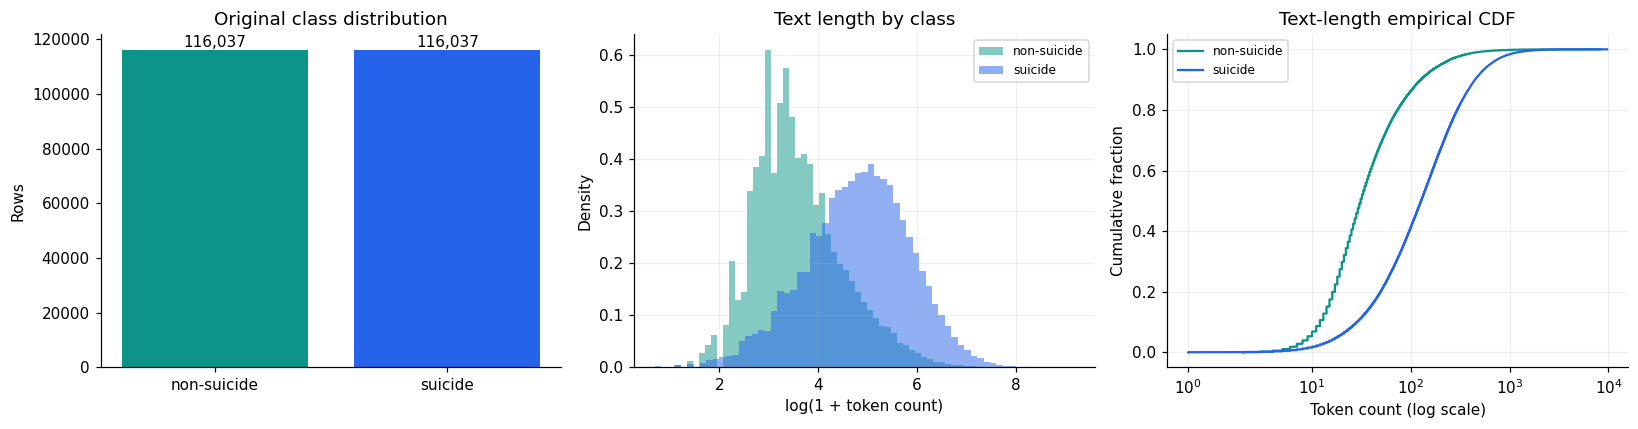

The original CSV contains **232,074 rows**. Positive prevalence is **50.00%**. Length quantiles and the empirical CDF describe the observed distribution without imposing a parametric family. Balanced labels do not imply similar text lengths, language, topics, or client populations.

In [4]:
raw_counts = raw_df['class'].value_counts().reindex(list(LABEL_MAP), fill_value=0)
raw_distribution = raw_counts.rename('rows').to_frame()
raw_distribution['fraction'] = raw_distribution['rows'] / raw_distribution['rows'].sum()
raw_distribution['percent'] = 100 * raw_distribution['fraction']
display(raw_distribution)
raw_length = raw_df['text'].fillna('').astype(str).str.count(r'\S+')
length_quantiles = [0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
raw_length_summary = raw_df.assign(tokens=raw_length).groupby('class')['tokens'].describe(
    percentiles=length_quantiles)
print('Original text lengths (whitespace-token counts):')
display(raw_length_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(raw_distribution.index, raw_distribution['rows'], color=['#0d9488', '#2563eb'])
axes[0].set(title='Original class distribution', ylabel='Rows')
for i, value in enumerate(raw_distribution['rows']):
    axes[0].text(i, value, f'{value:,}', ha='center', va='bottom')
for label, color in zip(LABEL_MAP, ['#0d9488', '#2563eb']):
    values = raw_length[raw_df['class'].eq(label)].to_numpy()
    axes[1].hist(np.log1p(values), bins=65, alpha=0.5, density=True, label=label, color=color)
    ordered = np.sort(values)
    axes[2].plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), label=label, color=color)
axes[1].set(title='Text length by class', xlabel='log(1 + token count)', ylabel='Density')
axes[2].set(title='Text-length empirical CDF', xlabel='Token count (log scale)', ylabel='Cumulative fraction', xscale='symlog')
for ax in axes[1:]:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
show_figure(fig, '01_original_distribution.png')
display(Markdown(
    f'The original CSV contains **{len(raw_df):,} rows**. Positive prevalence is '
    f'**{raw_distribution.loc["suicide", "fraction"]:.2%}**. Length quantiles and '
    'the empirical CDF describe the observed distribution without imposing a parametric family. '
    'Balanced labels do not imply similar text lengths, language, topics, or client populations.'))
del raw_df

### Split raw text before fitting; then clean each partition

The nominal split is 64% training, 16% validation and 20% test, stratified by label.
Cleaning uses fixed rules. Cleaned-text collisions are removed in the fixed order
train -> validation -> test; held-out rows never alter training rows. Counts removed
at each step and the final proportions are reported. Both raw and cleaned exact
duplicates are checked across splits. Author overlap and near-duplicates cannot be
excluded with the columns available in this CSV.

In [5]:
development_df, test_df = train_test_split(
    dataset, test_size=TEST_SIZE, random_state=SEED, stratify=dataset['label'])
train_df, validation_df = train_test_split(
    development_df, test_size=VALIDATION_FRACTION_OF_DEVELOPMENT,
    random_state=SEED, stratify=development_df['label'])
train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()

def assert_disjoint(partitions, column):
    seen = set()
    for frame in partitions:
        current = set(frame[column])
        assert not (seen & current), f'Overlap detected in {column}'
        seen.update(current)

assert_disjoint([train_df, validation_df, test_df], 'row_id')
assert_disjoint([train_df, validation_df, test_df], 'raw_key')
print('Raw split sizes:', {name: len(frame) for name, frame in
      [('train', train_df), ('validation', validation_df), ('test', test_df)]})

Raw split sizes: {'train': 148467, 'validation': 37117, 'test': 46397}


In [6]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFKC', html.unescape(text)).lower()
    text = text.replace('’', "'").replace('‘', "'")
    text = re.sub(r'<[^>]*>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', ' ', text)
    text = re.sub(r'(?<!\w)(?:u/|r/|@)[\w-]+', ' ', text)
    # Expand common English negations before punctuation removal.
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bshan't\b", 'shall not', text)
    text = re.sub(r"n['’]t\b", ' not', text)
    # Keep hashtag words, numbers and Unicode letters; no learned stopword list.
    text = re.sub(r'[^\w\s]', ' ', text)
    text = text.replace('_', ' ')
    return re.sub(r'\s+', ' ', text).strip()


def clean_partitions(partitions):
    # Fixed priority: train -> validation -> test.
    # Held-out texts can never cause a training row to be removed or changed.
    # Collisions created by cleaning are removed from the later partition.
    result, audit, seen = {}, [], set()
    for name, source in partitions.items():
        part = source.copy()
        part['cleaned_text'] = part['text'].map(clean_text)
        record = {'split': name, 'before': len(part)}
        empty = part['cleaned_text'].eq('')
        record['empty_after_cleaning'] = int(empty.sum())
        part = part.loc[~empty].copy()
        overlap = part['cleaned_text'].isin(seen)
        record['duplicates_of_earlier_split'] = int(overlap.sum())
        part = part.loc[~overlap].copy()
        # Inspect labels only within this partition, never across held-out boundaries.
        counts = part.groupby('cleaned_text', sort=False)['label'].nunique()
        conflicting = part['cleaned_text'].isin(counts.index[counts > 1])
        record['local_conflicting_label_rows'] = int(conflicting.sum())
        part = part.loc[~conflicting].copy()
        record['local_duplicates'] = int(part.duplicated('cleaned_text').sum())
        part = part.drop_duplicates('cleaned_text').reset_index(drop=True)
        if set(part['label']) != {0, 1}:
            raise ValueError(f'{name} lost a class after cleaning; inspect the quality audit.')
        seen.update(part['cleaned_text'])
        record['after'] = len(part)
        result[name] = part
        audit.append(record)
    return result, pd.DataFrame(audit).set_index('split')


partitions, cleaning_audit = clean_partitions(
    {'train': train_df, 'validation': validation_df, 'test': test_df})
train_df, validation_df, test_df = (partitions[name] for name in ['train', 'validation', 'test'])
assert_disjoint([train_df, validation_df, test_df], 'cleaned_text')
assert_disjoint([train_df, validation_df, test_df], 'row_id')

if train_df['label'].value_counts().min() < max(CLIENT_COUNTS):
    raise ValueError('Each training class needs at least max(CLIENT_COUNTS) rows.')
display(cleaning_audit)
split_table = pd.DataFrame({
    name: frame['label'].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in partitions.items()
}).T.rename(columns={0: 'non-suicide', 1: 'suicide'})
split_table['total'] = split_table.sum(axis=1)
split_table['positive_fraction'] = split_table['suicide'] / split_table['total']
display(split_table)
y_train = train_df['label'].to_numpy(dtype=np.int64)
y_validation = validation_df['label'].to_numpy(dtype=np.int64)
y_test = test_df['label'].to_numpy(dtype=np.int64)
assert_disjoint([train_df, validation_df, test_df], 'raw_key')
print('All row/text overlap checks passed.')

,before,empty_after_cleaning,duplicates_of_earlier_split,local_conflicting_label_rows,local_duplicates,after
split,,,,,,
train,148467,20,0,5,62,148380
validation,37117,1,28,0,2,37086
test,46397,5,47,0,3,46342


label,non-suicide,suicide,total,positive_fraction
train,74133,74247,148380,0.500384
validation,18525,18561,37086,0.500485
test,23145,23197,46342,0.500561


All row/text overlap checks passed.


Final cleaned-text length distribution by split and class:


count    mean     std  min   1%   25%    50%    75%    90%    95%      99%     max
split      label                                                                                      
test       0      23145.0   62.34  156.65  1.0  5.0  19.0   32.0   62.0  127.0  199.0   469.00  8221.0
           1      23197.0  212.85  271.97  1.0  8.0  62.0  132.0  265.0  468.0  656.0  1287.04  7502.0
train      0      74133.0   62.15  129.19  1.0  5.0  19.0   32.0   62.0  130.0  207.0   467.00  7395.0
           1      74247.0  212.02  262.99  1.0  8.0  63.0  134.0  262.0  465.0  656.7  1253.00  7913.0
validation 0      18525.0   61.96  140.54  1.0  5.0  19.0   32.0   62.0  128.0  200.0   463.76  7758.0
           1      18561.0  209.61  258.53  1.0  9.0  64.0  133.0  262.0  463.0  652.0  1188.00  9685.0

Training-only length cut points: [27.0, 63.0, 162.0] (searchsorted side="right")


length_bin,0,1,2,3
label,,,,
0,30520,25284,12920,5409
1,6097,12172,24105,31873


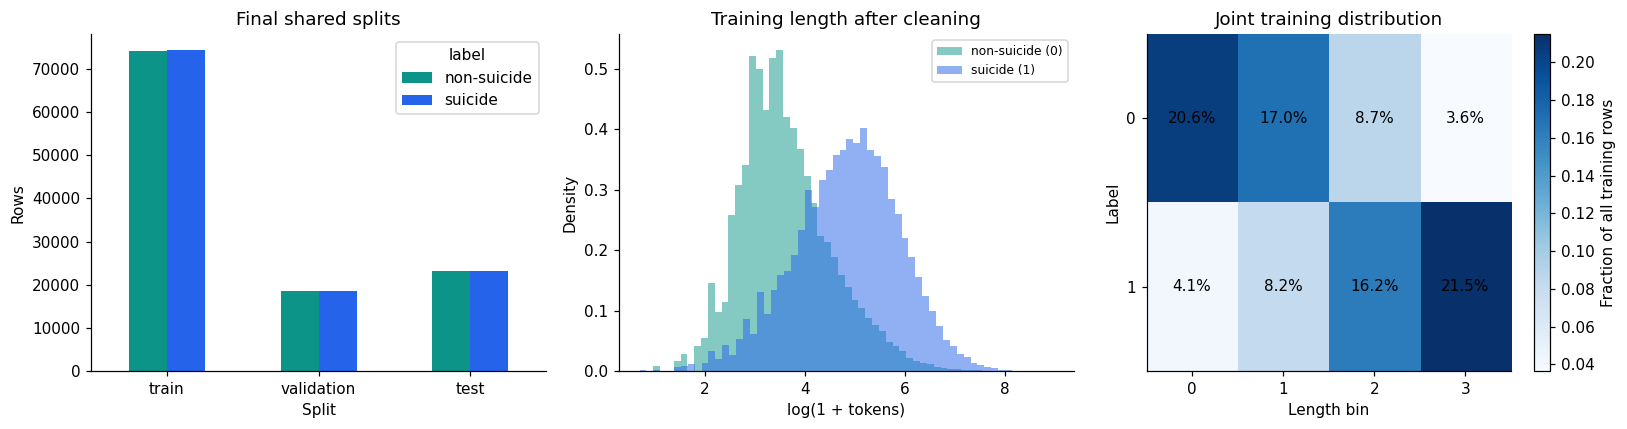

Most frequent training words by class (fixed English stop list removed for this display only):


word          occurrences        
label       0        1           0       1
rank                                      
1      filler     just       34393  131639
2        just     like       34096   84029
3        like     want       31983   82329
4        fuck     life       16320   72356
5        know     feel       15796   69615
6      people     know       14174   68451
7        want   people       13142   46914
8      really     time       11808   45516
9         day   really       11686   41858
10       time    going       10756   36725
11        did    think       10048   36660
12        got      did        9335   33799
13       feel  friends        9332   31194
14     school     help        9222   30147
15        mom    years        9125   29681

Split, row-ID, raw-text and cleaned-text disjointness checks passed.


In [7]:
for frame in partitions.values():
    frame['n_tokens'] = frame['cleaned_text'].str.count(r'\S+').astype(int)

print('Final cleaned-text length distribution by split and class:')
clean_length_summary = pd.concat(
    [frame.assign(split=name) for name, frame in partitions.items()], ignore_index=True
).groupby(['split', 'label'])['n_tokens'].describe(percentiles=length_quantiles)
display(clean_length_summary.round(2))

# Boundaries are estimated from training texts only, never from validation/test.
length_cuts = np.unique(np.quantile(train_df['n_tokens'], LENGTH_QUANTILES)).astype(float)
N_LENGTH_BINS = len(length_cuts) + 1
train_length_bins = np.searchsorted(length_cuts, train_df['n_tokens'].to_numpy(), side='right')
train_strata = y_train * N_LENGTH_BINS + train_length_bins
N_STRATA = 2 * N_LENGTH_BINS
stratum_counts = np.bincount(train_strata, minlength=N_STRATA)
if (stratum_counts == 0).any():
    raise ValueError('An empty label/length stratum exists; reduce the number of length bins.')
print('Training-only length cut points:', length_cuts.tolist(), '(searchsorted side="right")')
stratum_table = pd.crosstab(y_train, train_length_bins).reindex(
    index=[0, 1], columns=range(N_LENGTH_BINS), fill_value=0)
stratum_table.index.name, stratum_table.columns.name = 'label', 'length_bin'
display(stratum_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
split_table[['non-suicide', 'suicide']].plot.bar(
    ax=axes[0], color=['#0d9488', '#2563eb'], rot=0)
axes[0].set(title='Final shared splits', ylabel='Rows', xlabel='Split')
for label, color in [(0, '#0d9488'), (1, '#2563eb')]:
    lengths = train_df.loc[train_df['label'].eq(label), 'n_tokens']
    axes[1].hist(np.log1p(lengths), bins=60, density=True, alpha=0.5,
                 color=color, label=CLASS_NAMES[label])
axes[1].set(title='Training length after cleaning', xlabel='log(1 + tokens)', ylabel='Density')
axes[1].legend(fontsize=8)
image = axes[2].imshow(stratum_table.to_numpy() / len(train_df), cmap='Blues', aspect='auto')
axes[2].set(title='Joint training distribution', xlabel='Length bin', ylabel='Label',
             xticks=range(N_LENGTH_BINS), yticks=[0, 1])
for label in (0, 1):
    for b in range(N_LENGTH_BINS):
        axes[2].text(b, label, f'{stratum_table.loc[label, b] / len(train_df):.1%}',
                     ha='center', va='center', color='black')
fig.colorbar(image, ax=axes[2], label='Fraction of all training rows')
show_figure(fig, '02_clean_training_distribution.png')

# Descriptive training-only lexical summaries; these are not a shared fitted vectorizer.
top_word_rows = []
for label in (0, 1):
    counts = Counter(word for text in train_df.loc[train_df['label'].eq(label), 'cleaned_text']
                     for word in text.split() if len(word) >= 3 and word not in ENGLISH_STOP_WORDS)
    for rank, (word, count) in enumerate(counts.most_common(15), 1):
        top_word_rows.append({'label': label, 'rank': rank, 'word': word, 'occurrences': count})
top_words = pd.DataFrame(top_word_rows)
print('Most frequent training words by class (fixed English stop list removed for this display only):')
display(top_words.pivot(index='rank', columns='label', values=['word', 'occurrences']))
print('Split, row-ID, raw-text and cleaned-text disjointness checks passed.')

### Shared pipeline and evaluation rules

Word2Vec uses 100 dimensions, skip-gram, window 5, minimum count 2, and 5 epochs.
XGBoost uses the fixed parameters printed above. No hyperparameter search is run.
The centralized model fits on the entire training pool; a local model fits only on its
allocated rows. All stages use identical cleaning and feature construction rules.

A document vector is the frequency-weighted mean of the words known to that model:

$$z_k(x)=\frac{\sum_{w\in V_k} c(w,x)e_k(w)}{\sum_{w\in V_k}c(w,x)}.$$

Unknown words are ignored; a text with no known word gets a zero vector. The query
count cache below is a lossless input representation, with no fitted vocabulary
selection, IDF or embedding. Each model reads only columns in its own training
vocabulary. Independent embedding coordinates need no alignment because probabilities
are aggregated. Query labels never enter a client's fit or inference interface.

In [8]:
def stable_hash(value):
    return int.from_bytes(md5(str(value).encode('utf-8')).digest()[:4], 'little')

class SparseTokenBatch:
    """Input-only count cache. No fitted representation, pruning, or IDF."""
    def __init__(self, documents, row_ids=None):
        self.token_to_column = {}
        indptr, indices, counts = [0], [], []
        for document in documents:
            for token, count in Counter(document).items():
                column = self.token_to_column.setdefault(token, len(self.token_to_column))
                indices.append(column)
                counts.append(count)
            indptr.append(len(indices))
        self.counts = csr_matrix(
            (np.asarray(counts, dtype=np.float32), np.asarray(indices, dtype=np.int32),
             np.asarray(indptr, dtype=np.int64)),
            shape=(len(indptr) - 1, len(self.token_to_column)), dtype=np.float32)
        self.n_rows = self.counts.shape[0]
        self.total_tokens = float(self.counts.sum())
        if row_ids is None:
            row_ids = np.arange(self.n_rows)
        self.row_ids = np.asarray(row_ids, dtype=np.int64)
        if len(self.row_ids) != self.n_rows or len(np.unique(self.row_ids)) != self.n_rows:
            raise ValueError('Query row IDs must be unique and match the number of documents.')
        self.id_digest = sha256(self.row_ids.astype('<i8').tobytes()).hexdigest()

def local_embedding(batch, keyed_vectors):
    # Match query tokens to local training vocabulary; query-only tokens are ignored.
    query_columns, local_indices = [], []
    for token, local_index in keyed_vectors.key_to_index.items():
        column = batch.token_to_column.get(token)
        if column is not None:
            query_columns.append(column)
            local_indices.append(local_index)
    features = np.zeros((batch.n_rows, keyed_vectors.vector_size), dtype=np.float32)
    known_counts = np.zeros(batch.n_rows, dtype=np.float32)
    if query_columns:
        selected = batch.counts[:, query_columns]
        known_counts = np.asarray(selected.sum(axis=1)).ravel()
        features = np.asarray(selected @ keyed_vectors.vectors[local_indices], dtype=np.float32)
        np.divide(features, known_counts[:, None], out=features,
                  where=known_counts[:, None] > 0)
    if not np.isfinite(features).all():
        raise ValueError('Non-finite embedding values.')
    coverage = {
        'token_coverage': float(known_counts.sum() / batch.total_tokens)
                          if batch.total_tokens else 0.0,
        'all_oov_fraction': float(np.mean(known_counts == 0)),
    }
    return np.ascontiguousarray(features), coverage

class LocalTextXGB:
    """All learned state belongs to one client; fit accepts local rows only."""
    def __init__(self, seed):
        self.seed = int(seed)

    def fit(self, local_documents, local_labels):
        if set(np.unique(local_labels)) != {0, 1}:
            raise ValueError('Each client must have both classes.')
        started = time.perf_counter()
        self.w2v = Word2Vec(**W2V_CONFIG, seed=self.seed, hashfxn=stable_hash)
        self.w2v.build_vocab(local_documents)
        if not self.w2v.wv.key_to_index:
            raise ValueError('Empty local Word2Vec vocabulary; increase local data or reduce min_count.')
        self.w2v.train(local_documents, total_examples=len(local_documents),
                       epochs=W2V_CONFIG['epochs'])
        w2v_seconds = time.perf_counter() - started
        local_tokens = {token for document in local_documents for token in document}
        assert set(self.w2v.wv.key_to_index) <= local_tokens, 'Non-local word in fitted vocabulary.'
        local_batch = SparseTokenBatch(local_documents)
        started = time.perf_counter()
        features, train_coverage = local_embedding(local_batch, self.w2v.wv)
        embedding_seconds = time.perf_counter() - started
        self.xgb = XGBClassifier(**XGB_CONFIG, random_state=self.seed,
                                 n_jobs=XGB_THREADS_PER_CLIENT)
        started = time.perf_counter()
        self.xgb.fit(features, np.asarray(local_labels, dtype=np.int64))
        xgb_seconds = time.perf_counter() - started
        assert np.array_equal(self.xgb.classes_, np.array([0, 1]))
        p_train = self.xgb.predict_proba(features)[:, 1]
        return {
            'w2v_seconds': w2v_seconds, 'embedding_seconds': embedding_seconds,
            'xgb_seconds': xgb_seconds,
            'fit_seconds': w2v_seconds + embedding_seconds + xgb_seconds,
            'train_accuracy_at_05': float(accuracy_score(local_labels, p_train >= 0.5)),
            'vocabulary_size': len(self.w2v.wv),
            'train_token_coverage': train_coverage['token_coverage'],
        }

    def predict_batch(self, batch):
        started = time.perf_counter()
        features, coverage = local_embedding(batch, self.w2v.wv)
        locations = np.flatnonzero(self.xgb.classes_ == 1)
        if len(locations) != 1:
            raise ValueError('Class 1 missing from the local model.')
        probabilities = self.xgb.predict_proba(features)[:, int(locations[0])].astype(np.float32)
        if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
            raise ValueError('Invalid local probabilities.')
        return probabilities, coverage, time.perf_counter() - started

preparation_started = time.perf_counter()
train_documents = train_df['cleaned_text'].str.split().tolist()
validation_documents = validation_df['cleaned_text'].str.split().tolist()
test_documents = test_df['cleaned_text'].str.split().tolist()
validation_batch = SparseTokenBatch(validation_documents, validation_df['row_id'])
test_batch = SparseTokenBatch(test_documents, test_df['row_id'])
query_preparation_seconds = time.perf_counter() - preparation_started
del validation_documents, test_documents
print(f'Fixed tokenization/query-cache preparation: {query_preparation_seconds:.2f} s')
print('No Word2Vec has been trained yet.')

Fixed tokenization/query-cache preparation: 7.75 s
No Word2Vec has been trained yet.


In [9]:
def aggregate_probabilities(client_probabilities, client_sizes):
    values = np.asarray(client_probabilities)
    sizes = np.asarray(client_sizes, dtype=np.float64)
    if values.ndim != 2 or values.shape[0] != len(sizes) or values.shape[1] == 0:
        raise ValueError('Expected probabilities with shape (clients, query_rows).')
    if not np.isfinite(values).all() or np.any((values < 0) | (values > 1)):
        raise ValueError('Client probability outside [0, 1].')
    if not np.isfinite(sizes).all() or np.any(sizes <= 0):
        raise ValueError('Client sizes must be finite and positive.')
    weights = sizes / sizes.sum()
    result = np.asarray(weights @ values.astype(np.float64), dtype=np.float64)
    assert np.isfinite(result).all() and np.all((result >= 0) & (result <= 1))
    return result

def metric_summary(y_true, probabilities, threshold):
    predictions = (np.asarray(probabilities) >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, predictions),
        'balanced_accuracy': balanced_accuracy_score(y_true, predictions),
        'precision_positive': precision_score(y_true, predictions, zero_division=0),
        'recall_positive': recall_score(y_true, predictions, zero_division=0),
        'f1_positive': f1_score(y_true, predictions, zero_division=0),
        'f1_macro': f1_score(y_true, predictions, average='macro', zero_division=0),
        'f1_weighted': f1_score(y_true, predictions, average='weighted', zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'average_precision': average_precision_score(y_true, probabilities),
        'brier_score': brier_score_loss(y_true, probabilities),
        'log_loss': log_loss(y_true, probabilities, labels=[0, 1]),
        'specificity': tn / (tn + fp) if tn + fp else 0.0,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }


def select_threshold(y_true, probabilities):
    # Counts on validation only; tie-breaks are fixed before seeing results.
    labels = np.asarray(y_true, dtype=bool)
    rows = []
    for cutoff in THRESHOLDS:
        pred = np.asarray(probabilities) >= cutoff
        tp = int(np.sum(pred & labels))
        fp = int(np.sum(pred & ~labels))
        fn = int(np.sum(~pred & labels))
        tn = len(labels) - tp - fp - fn
        rows.append({'threshold': float(cutoff), 'accuracy': (tp + tn) / len(labels),
            'precision_positive': tp / (tp + fp) if tp + fp else 0.0,
            'recall_positive': tp / (tp + fn) if tp + fn else 0.0,
            'f1_positive': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0})
    curve = pd.DataFrame(rows)
    ranked = curve.assign(distance_to_half=(curve['threshold'] - 0.5).abs()).sort_values(
        ['f1_positive', 'precision_positive', 'distance_to_half', 'threshold'],
        ascending=[False, False, True, True], kind='mergesort')
    return float(ranked.iloc[0]['threshold']), curve


def finalize_report(mode, n_clients, seed, validation_p, test_p, local_summary, wall_seconds):
    # Freeze the threshold using validation before calculating any test metric.
    threshold, threshold_curve = select_threshold(y_validation, validation_p)
    rows = []
    for split, labels, probability in [('validation', y_validation, validation_p), ('test', y_test, test_p)]:
        for policy, cutoff in [('fixed_0.50', 0.5), ('validation_selected', threshold)]:
            rows.append({'split': split, 'policy': policy, **metric_summary(labels, probability, cutoff)})
    return {'mode': mode, 'n_clients': n_clients, 'seed': seed,
        'threshold': threshold, 'threshold_curve': threshold_curve,
        'metrics': pd.DataFrame(rows).set_index(['split', 'policy']),
        'validation_probabilities': validation_p, 'test_probabilities': test_p,
        'local_summary': local_summary, 'pipeline_wall_seconds': wall_seconds,
        'fit_seconds_sum': float(local_summary['fit_seconds'].sum()),
        'test_ids_digest': test_batch.id_digest,
        'validation_ids_digest': validation_batch.id_digest}


def show_report(report):
    print(f'{report["mode"]} | K={report["n_clients"]} | seed={report["seed"]}')
    print(f'Validation-selected threshold: {report["threshold"]:.2f}')
    columns = ['accuracy', 'precision_positive', 'recall_positive', 'f1_positive',
               'f1_macro', 'roc_auc', 'average_precision', 'brier_score', 'fn', 'fp']
    display(report['metrics'][columns].round(4))
    print('Test classification report at the validation-selected threshold:')
    print(classification_report(y_test, report['test_probabilities'] >= report['threshold'],
        labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
    local = report['local_summary']
    display(local[['n_train', 'positive_fraction', 'vocabulary_size',
                   'test_token_coverage', 'test_all_oov_fraction']].agg(['min', 'mean', 'max']).round(4))
    print(f'Pipeline wall time: {report["pipeline_wall_seconds"]:.2f} s | '
          f'Sum of model fit times: {report["fit_seconds_sum"]:.2f} s')

## Stage 2 - Centralized XGBoost baseline

Train the same Word2Vec + XGBoost pipeline on all training rows. The baseline receives
no extra validation or test training data. This establishes the cost of splitting the
training pool and using local representations plus a probability ensemble.

Positive-class F1 selects the optional threshold on validation. Ties prefer greater
precision, then proximity to 0.50, then the smaller threshold. ROC-AUC and Average
Precision (AP) use continuous probabilities. AP is not trapezoidal PR area.

In [10]:
central_reports = []
embedding_invariant_passed = False
for run_seed in REPEAT_SEEDS:
    started = time.perf_counter()
    central = LocalTextXGB(seed=run_seed)
    fit_info = central.fit(train_documents, y_train)
    validation_p, validation_coverage, _ = central.predict_batch(validation_batch)
    test_p, test_coverage, _ = central.predict_batch(test_batch)
    wall_seconds = time.perf_counter() - started

    # Check the accelerated embedding against a direct mean, repeated tokens and all-OOV input.
    words = central.w2v.wv.index_to_key[:2]
    unknown = '__out_of_vocabulary_invariant_token__'
    assert unknown not in central.w2v.wv
    probe_documents = [[words[0], words[0], words[1]], [unknown], []]
    probe, probe_coverage = local_embedding(SparseTokenBatch(probe_documents), central.w2v.wv)
    expected = np.zeros_like(probe)
    expected[0] = np.mean([central.w2v.wv[w] for w in probe_documents[0]], axis=0)
    np.testing.assert_allclose(probe, expected, rtol=2e-6, atol=2e-7)
    assert probe_coverage['all_oov_fraction'] == 2 / 3
    embedding_invariant_passed = True

    local_summary = pd.DataFrame([{'client_id': 1, 'n_train': len(y_train),
        'positive_fraction': float(y_train.mean()), **fit_info,
        'test_token_coverage': test_coverage['token_coverage'],
        'test_all_oov_fraction': test_coverage['all_oov_fraction'], 'weight': 1.0}])
    report = finalize_report('Centralized', 1, run_seed, validation_p, test_p,
                             local_summary, wall_seconds)
    central_reports.append(report)
    show_report(report)
    del central
    gc.collect()
print('Direct-mean embedding, repeated-token and all-OOV checks passed.')

Centralized | K=1 | seed=42
Validation-selected threshold: 0.44


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.9233              0.9216           0.9254       0.9235    0.9233   0.9763             0.9758       0.0575  1385  1461
           validation_selected    0.9237              0.9118           0.9383       0.9248    0.9236   0.9763             0.9758       0.0575  1146  1685
test       fixed_0.50             0.9197              0.9188           0.9209       0.9199    0.9197   0.9752             0.9744       0.0591  1835  1887
           validation_selected    0.9199              0.9095           0.9329       0.9210    0.9199   0.9752             0.9744       0.0591  1557  2153

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9310    0.9070    0.9188     23145
    suicide (1)     0.9095    0.9329    0.9210     23197

       accuracy                         0.9199     46342
      macro avg     0.9202    0.9199    0.9199     46342
   weighted avg     0.9202    0.9199    0.9199     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,148380.0,0.5004,53781.0,0.9949,0.0003
mean,148380.0,0.5004,53781.0,0.9949,0.0003
max,148380.0,0.5004,53781.0,0.9949,0.0003


Pipeline wall time: 484.63 s | Sum of model fit times: 477.52 s
Direct-mean embedding, repeated-token and all-OOV checks passed.


## Stage 3 - Similar client distributions (IID-style)

The full joint distribution of text and label cannot be characterized by label balance
alone. This experiment preserves **label x training-length-bin** proportions and verifies
them numerically. Random assignment within each stratum approximates similarity in
unmeasured features. It does not prove identical topic, author or semantic distributions.

For each of the eight joint strata, shuffle its training rows and allocate nearly equal
portions to clients. Rotate remainder assignments to keep total client sizes within one
row. Every training row is used exactly once per experiment. Validation/test never enter
the client allocations.

Diagnostics below include class prevalence, length-bin proportions, client sizes,
Jensen-Shannon divergence (base 2, squared distance, range 0-1), and conditional length
divergence within each class. A value near zero means the **measured** distributions match.

IID-style partition diagnostics:


,mode,n_clients,seed,min_rows,mean_rows,max_rows,size_cv,positive_fraction_min,positive_fraction_max,mean_label_js_bits,mean_joint_js_bits,mean_conditional_length_js_bits,weighted_joint_js_bits
0,IID,10,42,14838,14838.0,14838,0.000000,0.500337,0.500404,0.0,0.000000,0.000000,0.000000
1,IID,20,42,7419,7419.0,7419,0.000000,0.500337,0.500472,0.0,0.000000,0.000000,0.000000
2,IID,50,42,2967,2967.6,2968,0.000165,0.500169,0.500506,0.0,0.000000,0.000000,0.000000
3,IID,100,42,1483,1483.8,1484,0.000270,0.500000,0.500674,0.0,0.000001,0.000001,0.000001


All training rows are allocated once; pooled distributions match training exactly.


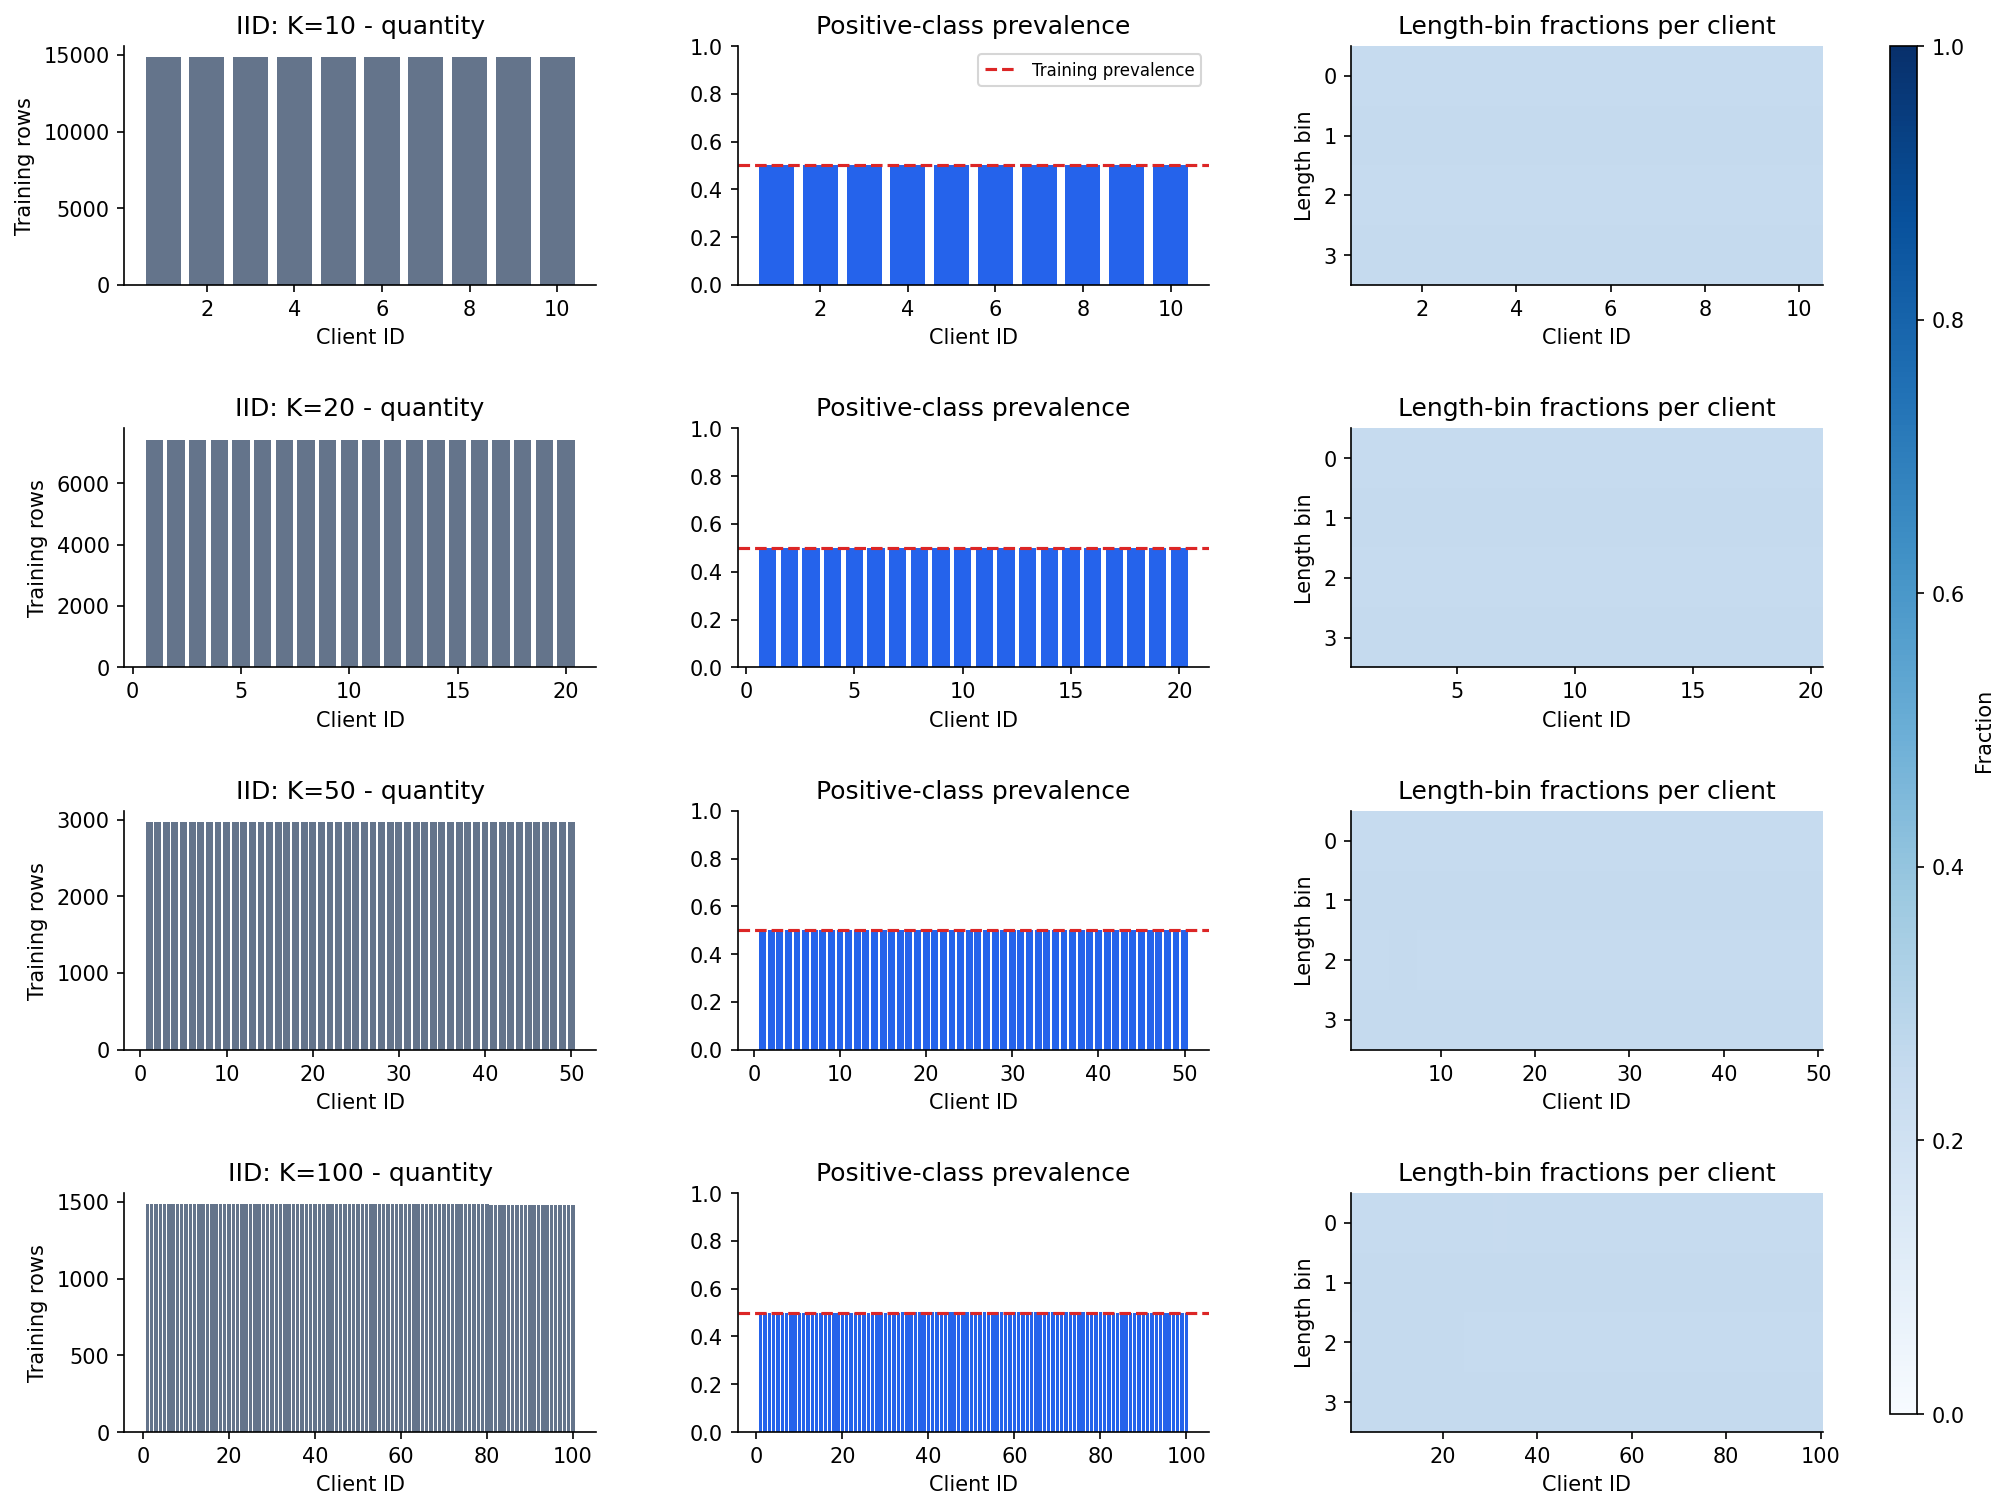

In [11]:
def check_client_plan(plan, labels, n_clients):
    assert len(plan) == n_clients
    joined = np.concatenate(plan)
    np.testing.assert_array_equal(np.sort(joined), np.arange(len(labels)))
    assert all(len(pos) > 0 and set(labels[pos]) == {0, 1} for pos in plan)


def iid_client_indices(strata, n_clients, seed):
    rng = np.random.default_rng(seed)
    buckets = [[] for _ in range(n_clients)]
    offset = 0
    for stratum in range(N_STRATA):
        positions = np.flatnonzero(strata == stratum)
        rng.shuffle(positions)
        order = (np.arange(n_clients) + offset) % n_clients
        for client_id, portion in zip(order, np.array_split(positions, n_clients)):
            buckets[int(client_id)].extend(portion.tolist())
        offset = (offset + len(positions) % n_clients) % n_clients
    plan = [np.asarray(bucket, dtype=np.int64) for bucket in buckets]
    for positions in plan:
        rng.shuffle(positions)
    check_client_plan(plan, y_train, n_clients)
    assert max(map(len, plan)) - min(map(len, plan)) <= 1
    return plan


def noniid_client_indices(strata, n_clients, seed):
    if NONIID_ALPHA <= 0 or NONIID_QUANTITY_SIGMA < 0 or NONIID_MIN_PER_STRATUM < 1:
        raise ValueError('Invalid heterogeneity settings.')
    rng = np.random.default_rng(seed)
    quantity = rng.lognormal(mean=-0.5 * NONIID_QUANTITY_SIGMA ** 2,
                            sigma=NONIID_QUANTITY_SIGMA, size=n_clients)
    buckets = [[] for _ in range(n_clients)]
    for stratum in range(N_STRATA):
        positions = np.flatnonzero(strata == stratum)
        rng.shuffle(positions)
        floor_count = n_clients * NONIID_MIN_PER_STRATUM
        if len(positions) < floor_count:
            raise ValueError('Not enough rows for the non-IID floor; reduce it or use fewer clients.')
        floor = positions[:floor_count].reshape(n_clients, NONIID_MIN_PER_STRATUM)
        remainder = positions[floor_count:]
        for client_id in range(n_clients):
            buckets[client_id].extend(floor[client_id].tolist())
        preference = rng.dirichlet(np.full(n_clients, NONIID_ALPHA)) * quantity
        preference /= preference.sum()
        counts = rng.multinomial(len(remainder), preference)
        boundaries = np.r_[0, np.cumsum(counts)]
        for client_id in range(n_clients):
            buckets[client_id].extend(remainder[boundaries[client_id]:boundaries[client_id + 1]].tolist())
    plan = [np.asarray(bucket, dtype=np.int64) for bucket in buckets]
    for positions in plan:
        rng.shuffle(positions)
    check_client_plan(plan, y_train, n_clients)
    assert min(map(len, plan)) >= N_STRATA * NONIID_MIN_PER_STRATUM
    return plan


def js_divergence(p, q):
    return float(jensenshannon(np.asarray(p, dtype=float), np.asarray(q, dtype=float), base=2) ** 2)


def describe_plan(plan, mode, n_clients, seed):
    global_joint = np.bincount(train_strata, minlength=N_STRATA).astype(float)
    global_joint /= global_joint.sum()
    global_label = np.bincount(y_train, minlength=2) / len(y_train)
    global_length = np.bincount(train_length_bins, minlength=N_LENGTH_BINS) / len(y_train)
    rows = []
    for client_id, positions in enumerate(plan, 1):
        labels = y_train[positions]
        joint = np.bincount(train_strata[positions], minlength=N_STRATA) / len(positions)
        label_p = np.bincount(labels, minlength=2) / len(positions)
        length_p = np.bincount(train_length_bins[positions], minlength=N_LENGTH_BINS) / len(positions)
        conditional_js = 0.0
        for label in (0, 1):
            sl = slice(label * N_LENGTH_BINS, (label + 1) * N_LENGTH_BINS)
            conditional_js += label_p[label] * js_divergence(joint[sl], global_joint[sl])
        row = {'mode': mode, 'n_clients': n_clients, 'seed': seed, 'client_id': client_id,
            'n_train': len(positions), 'n_negative': int(np.sum(labels == 0)),
            'n_positive': int(labels.sum()), 'positive_fraction': float(labels.mean()),
            'weight': len(positions) / len(y_train),
            'mean_tokens': float(train_df.iloc[positions]['n_tokens'].mean()),
            'median_tokens': float(train_df.iloc[positions]['n_tokens'].median()),
            'label_js_bits': js_divergence(label_p, global_label),
            'length_js_bits': js_divergence(length_p, global_length),
            'joint_js_bits': js_divergence(joint, global_joint),
            'conditional_length_js_bits': conditional_js}
        row.update({f'length_bin_{b}': float(length_p[b]) for b in range(N_LENGTH_BINS)})
        row.update({f'joint_stratum_{s}': float(joint[s]) for s in range(N_STRATA)})
        rows.append(row)
    frame = pd.DataFrame(rows)
    np.testing.assert_allclose(frame['weight'].sum(), 1.0)
    # Size-weighted pooled client distributions must exactly reconstruct training.
    weighted_joint = frame['weight'].to_numpy() @ frame[[f'joint_stratum_{s}' for s in range(N_STRATA)]].to_numpy()
    np.testing.assert_allclose(weighted_joint, global_joint, atol=1e-12)
    return frame


def partition_summary_table(table):
    rows = []
    for (mode, n_clients, seed), frame in table.groupby(['mode', 'n_clients', 'seed'], sort=False):
        rows.append({'mode': mode, 'n_clients': n_clients, 'seed': seed,
            'min_rows': int(frame['n_train'].min()), 'mean_rows': frame['n_train'].mean(),
            'max_rows': int(frame['n_train'].max()),
            'size_cv': frame['n_train'].std(ddof=0) / frame['n_train'].mean(),
            'positive_fraction_min': frame['positive_fraction'].min(),
            'positive_fraction_max': frame['positive_fraction'].max(),
            'mean_label_js_bits': frame['label_js_bits'].mean(),
            'mean_joint_js_bits': frame['joint_js_bits'].mean(),
            'mean_conditional_length_js_bits': frame['conditional_length_js_bits'].mean(),
            'weighted_joint_js_bits': np.average(frame['joint_js_bits'], weights=frame['n_train'])})
    return pd.DataFrame(rows)


def plot_partitions(table, mode, filename):
    first_seed = REPEAT_SEEDS[0]
    fig, axes = plt.subplots(len(CLIENT_COUNTS), 3, figsize=(15, 3 * len(CLIENT_COUNTS)), squeeze=False)
    for row, n_clients in enumerate(CLIENT_COUNTS):
        frame = table.query('mode == @mode and n_clients == @n_clients and seed == @first_seed').sort_values('client_id')
        x = frame['client_id'].to_numpy()
        axes[row, 0].bar(x, frame['n_train'], color='#64748b')
        axes[row, 0].set(title=f'{mode}: K={n_clients} - quantity', ylabel='Training rows')
        axes[row, 1].bar(x, frame['positive_fraction'], color='#2563eb')
        axes[row, 1].axhline(y_train.mean(), color='#dc2626', linestyle='--', label='Training prevalence')
        axes[row, 1].set(title='Positive-class prevalence', ylim=(0, 1))
        matrix = frame[[f'length_bin_{b}' for b in range(N_LENGTH_BINS)]].to_numpy().T
        im = axes[row, 2].imshow(matrix, aspect='auto', vmin=0, vmax=1, cmap='Blues',
                                 extent=[0.5, n_clients + 0.5, N_LENGTH_BINS - 0.5, -0.5])
        axes[row, 2].set(title='Length-bin fractions per client', ylabel='Length bin', yticks=range(N_LENGTH_BINS))
        for ax in axes[row]:
            ax.set_xlabel('Client ID')
    axes[0, 1].legend(fontsize=8)
    # Reserve a separate colorbar axis so labels never overlap the heatmaps.
    fig.subplots_adjust(wspace=0.3, hspace=0.6, right=0.88)
    colorbar_axis = fig.add_axes([0.91, 0.12, 0.012, 0.76])
    fig.colorbar(im, cax=colorbar_axis, label='Fraction')
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


client_plans, plan_tables, scenario_reports = {}, [], {}
for n_clients in CLIENT_COUNTS:
    for run_seed in REPEAT_SEEDS:
        plan = iid_client_indices(train_strata, n_clients, run_seed)
        client_plans[('IID', n_clients, run_seed)] = plan
        plan_tables.append(describe_plan(plan, 'IID', n_clients, run_seed))
iid_partition_table = pd.concat(plan_tables, ignore_index=True)
print('IID-style partition diagnostics:')
display(partition_summary_table(iid_partition_table).round(6))
assert iid_partition_table['joint_js_bits'].max() < 0.001
print('All training rows are allocated once; pooled distributions match training exactly.')
plot_partitions(iid_partition_table, 'IID', '03_iid_partitions.png')

### Run the local models and server ensemble

All clients participate. Size-weighted aggregation is fixed in advance and uses no
validation or test performance weights. The simulated client interface returns only
probabilities, row-order digests and diagnostics. Client labels are used only locally.
The coordinator owns validation labels for threshold selection and test labels for
evaluation. Raw training texts remain outside the server aggregation function.

Runtime measures this single-process simulation, including local fitting and inference.
Concurrent client fit times overlap; their sum is not distributed network latency.

In [12]:
def train_client(client_id, positions, run_seed, validation_queries, test_queries):
    # No held-out labels, other-client training rows, or global embedding enters this function.
    documents = [train_documents[int(index)] for index in positions]
    labels = y_train[positions]
    client = LocalTextXGB(seed=run_seed + 1009 * (client_id + 1))
    fit_info = client.fit(documents, labels)
    validation_p, validation_coverage, validation_seconds = client.predict_batch(validation_queries)
    test_p, test_coverage, test_seconds = client.predict_batch(test_queries)
    info = {
        'client_id': client_id + 1, 'n_train': len(positions),
        'n_positive': int(labels.sum()), 'positive_fraction': float(labels.mean()),
        **fit_info,
        'validation_token_coverage': validation_coverage['token_coverage'],
        'test_token_coverage': test_coverage['token_coverage'],
        'test_all_oov_fraction': test_coverage['all_oov_fraction'],
        'validation_predict_seconds': validation_seconds,
        'test_predict_seconds': test_seconds,
    }
    return {
        'client_id': client_id, 'info': info,
        'validation_p': validation_p, 'test_p': test_p,
        'validation_ids_digest': validation_queries.id_digest,
        'test_ids_digest': test_queries.id_digest,
        'client': client if RETAIN_CLIENT_MODELS else None,
    }


def run_federated(mode, n_clients, run_seed):
    started = time.perf_counter()
    plan = client_plans[(mode, n_clients, run_seed)]
    packets = [None] * n_clients
    print(f'{mode}, K={n_clients}, seed={run_seed}: training {n_clients} local pipelines', flush=True)
    with ThreadPoolExecutor(max_workers=min(MAX_PARALLEL_CLIENTS, n_clients)) as executor:
        futures = [executor.submit(train_client, client_id, positions, run_seed,
                                   validation_batch, test_batch)
                   for client_id, positions in enumerate(plan)]
        for completed, future in enumerate(as_completed(futures), 1):
            packet = future.result()
            packets[packet['client_id']] = packet
            if completed % max(1, n_clients // 5) == 0:
                print(f'  completed {completed}/{n_clients}', flush=True)
    for packet in packets:
        assert packet['validation_ids_digest'] == validation_batch.id_digest
        assert packet['test_ids_digest'] == test_batch.id_digest
    local_summary = pd.DataFrame([p['info'] for p in packets])
    sizes = local_summary['n_train'].to_numpy(dtype=int)
    assert sizes.sum() == len(y_train)
    local_summary['weight'] = sizes / sizes.sum()
    val_matrix = np.vstack([p['validation_p'] for p in packets])
    test_matrix = np.vstack([p['test_p'] for p in packets])
    validation_p = aggregate_probabilities(val_matrix, sizes)
    test_p = aggregate_probabilities(test_matrix, sizes)
    # Independent accumulation verifies client order and size-weighted aggregation.
    direct = sum(float(sizes[k]) / sizes.sum() * test_matrix[k].astype(float) for k in range(n_clients))
    np.testing.assert_allclose(test_p, direct, rtol=1e-12, atol=1e-12)
    report = finalize_report(mode, n_clients, run_seed, validation_p, test_p,
                             local_summary, time.perf_counter() - started)
    report['probability_response_mib'] = float((val_matrix.nbytes + test_matrix.nbytes) / 1024 ** 2)
    if RETAIN_CLIENT_MODELS:
        report['clients'] = [packet['client'] for packet in packets]
    return report


def run_and_report(mode, n_clients):
    reports = []
    for run_seed in REPEAT_SEEDS:
        report = run_federated(mode, n_clients, run_seed)
        reports.append(report)
        show_report(report)
        gc.collect()
    scenario_reports[(mode, n_clients)] = reports

### IID - 10 clients

Independent local training and a shared held-out evaluation.

In [13]:
run_and_report('IID', 10)

IID, K=10, seed=42: training 10 local pipelines
  completed 2/10
  completed 4/10
  completed 6/10
  completed 8/10
  completed 10/10
IID | K=10 | seed=42
Validation-selected threshold: 0.46


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.9181              0.9147           0.9225       0.9186    0.9181   0.9734             0.9726       0.0615  1439  1597
           validation_selected    0.9182              0.9075           0.9314       0.9193    0.9181   0.9734             0.9726       0.0615  1273  1762
test       fixed_0.50             0.9151              0.9124           0.9186       0.9154    0.9151   0.9724             0.9718       0.0629  1889  2047
           validation_selected    0.9143              0.9040           0.9273       0.9155    0.9143   0.9724             0.9718       0.0629  1687  2285

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9252    0.9013    0.9131     23145
    suicide (1)     0.9040    0.9273    0.9155     23197

       accuracy                         0.9143     46342
      macro avg     0.9146    0.9143    0.9143     46342
   weighted avg     0.9146    0.9143    0.9143     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,14838.0,0.5003,17281.0,0.9857,0.0004
mean,14838.0,0.5004,17598.3,0.9859,0.0004
max,14838.0,0.5004,18093.0,0.9863,0.0005


Pipeline wall time: 168.74 s | Sum of model fit times: 565.38 s


### IID - 20 clients

Independent local training and a shared held-out evaluation.

In [14]:
run_and_report('IID', 20)

IID, K=20, seed=42: training 20 local pipelines
  completed 4/20
  completed 8/20
  completed 12/20
  completed 16/20
  completed 20/20
IID | K=20 | seed=42
Validation-selected threshold: 0.47


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.9115              0.9074           0.9168       0.9120    0.9115   0.9695             0.9689       0.0662  1545  1737
           validation_selected    0.9114              0.9014           0.9240       0.9125    0.9114   0.9695             0.9689       0.0662  1411  1876
test       fixed_0.50             0.9087              0.9056           0.9127       0.9092    0.9087   0.9685             0.9680       0.0676  2025  2206
           validation_selected    0.9088              0.8994           0.9209       0.9100    0.9088   0.9685             0.9680       0.0676  1835  2390

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9188    0.8967    0.9076     23145
    suicide (1)     0.8994    0.9209    0.9100     23197

       accuracy                         0.9088     46342
      macro avg     0.9091    0.9088    0.9088     46342
   weighted avg     0.9091    0.9088    0.9088     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,7419.0,0.5003,12063.00,0.9793,0.0004
mean,7419.0,0.5004,12420.95,0.9799,0.0005
max,7419.0,0.5005,12955.00,0.9809,0.0005


Pipeline wall time: 172.76 s | Sum of model fit times: 646.01 s


### IID - 50 clients

Independent local training and a shared held-out evaluation.

In [15]:
run_and_report('IID', 50)

IID, K=50, seed=42: training 50 local pipelines
  completed 10/50
  completed 20/50
  completed 30/50
  completed 40/50
  completed 50/50
IID | K=50 | seed=42
Validation-selected threshold: 0.54


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.8933              0.8857           0.9033       0.8944    0.8933   0.9591             0.9592       0.0782  1794  2164
           validation_selected    0.8952              0.8970           0.8931       0.8950    0.8952   0.9591             0.9592       0.0782  1984  1904
test       fixed_0.50             0.8926              0.8864           0.9010       0.8936    0.8926   0.9583             0.9584       0.0790  2297  2678
           validation_selected    0.8925              0.8956           0.8889       0.8922    0.8925   0.9583             0.9584       0.0790  2578  2403

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.8895    0.8962    0.8928     23145
    suicide (1)     0.8956    0.8889    0.8922     23197

       accuracy                         0.8925     46342
      macro avg     0.8925    0.8925    0.8925     46342
   weighted avg     0.8925    0.8925    0.8925     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,2967.0,0.5002,7344.00,0.9666,0.0005
mean,2967.6,0.5004,7658.76,0.9677,0.0006
max,2968.0,0.5005,8062.00,0.9688,0.0007


Pipeline wall time: 149.43 s | Sum of model fit times: 544.33 s


### IID - 100 clients

Independent local training and a shared held-out evaluation.

In [16]:
run_and_report('IID', 100)

IID, K=100, seed=42: training 100 local pipelines
  completed 20/100
  completed 40/100
  completed 60/100
  completed 80/100
  completed 100/100
IID | K=100 | seed=42
Validation-selected threshold: 0.56


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.8706              0.8566           0.8905       0.8732    0.8705   0.9438             0.9454       0.0939  2032  2767
           validation_selected    0.8741              0.8760           0.8719       0.8740    0.8741   0.9438             0.9454       0.0939  2378  2290
test       fixed_0.50             0.8695              0.8565           0.8880       0.8720    0.8694   0.9435             0.9450       0.0942  2598  3450
           validation_selected    0.8726              0.8761           0.8683       0.8722    0.8726   0.9435             0.9450       0.0942  3054  2849

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.8692    0.8769    0.8730     23145
    suicide (1)     0.8761    0.8683    0.8722     23197

       accuracy                         0.8726     46342
      macro avg     0.8726    0.8726    0.8726     46342
   weighted avg     0.8727    0.8726    0.8726     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,1483.0,0.5000,4853.00,0.9521,0.0006
mean,1483.8,0.5004,5197.49,0.9543,0.0007
max,1484.0,0.5007,5612.00,0.9573,0.0008


Pipeline wall time: 190.51 s | Sum of model fit times: 693.19 s


## Stage 4 - Different client distributions (non-IID)

This is a controlled stress test of **statistical heterogeneity**, not a claim to
reconstruct actual institutions. The CSV supplies text and a binary label, without
verified client, author, timestamp or hospital identifiers.

For client $k$, draw a quantity propensity $q_k$ from a lognormal distribution with
$\sigma=0.80$. For every joint label/length stratum $s$, draw
$d_s\sim\mathrm{Dirichlet}(\alpha\mathbf{1}_K)$, with $\alpha=0.30$, and assign the
remaining rows with multinomial probabilities proportional to $q_k d_{s,k}$.

Before that draw, reserve **8 rows of each joint stratum per client**, giving a small
minimum of 64 rows with four length bins and two labels. This makes every local
two-class XGBoost fit well-defined. The floor is disclosed, and its dataset fraction
is printed below; clients with an entirely missing class are outside this design.

This creates **joint label/text-length skew and quantity imbalance**. Lower alpha
generally increases concentration; the realized diagnostics, rather than alpha alone,
establish whether clients differ. Length skew is a measurable text-feature proxy, not
proof of a semantic or real clinical domain shift. These factors vary together here,
so their separate causal contributions cannot be identified from this comparison.
The training pool, preprocessing, model parameters, weights and held-out sets stay
the same as in the IID experiments.

,mode,n_clients,seed,min_rows,mean_rows,max_rows,size_cv,positive_fraction_min,positive_fraction_max,mean_label_js_bits,mean_joint_js_bits,mean_conditional_length_js_bits,weighted_joint_js_bits
4,Non-IID,10,42,2259,14838.0,28506,0.605982,0.049840,0.992809,0.092155,0.301044,0.224344,0.314248
5,Non-IID,20,42,1525,7419.0,27637,0.852628,0.063458,0.898197,0.070970,0.298492,0.238670,0.281476
6,Non-IID,50,42,193,2967.6,16867,1.056667,0.032694,0.984619,0.065422,0.250804,0.199676,0.250982
7,Non-IID,100,42,171,1483.8,13328,1.144647,0.037574,0.961249,0.052461,0.220574,0.179015,0.222496


Uniform floor used before heterogeneous allocation:


,n_clients,reserved_rows,reserved_fraction
0,10,640,0.004313
1,20,1280,0.008626
2,50,3200,0.021566
3,100,6400,0.043132


Non-IID label, joint and within-class length divergences exceed the matched IID values.
All allocations reconstruct exactly the same pooled training distribution.


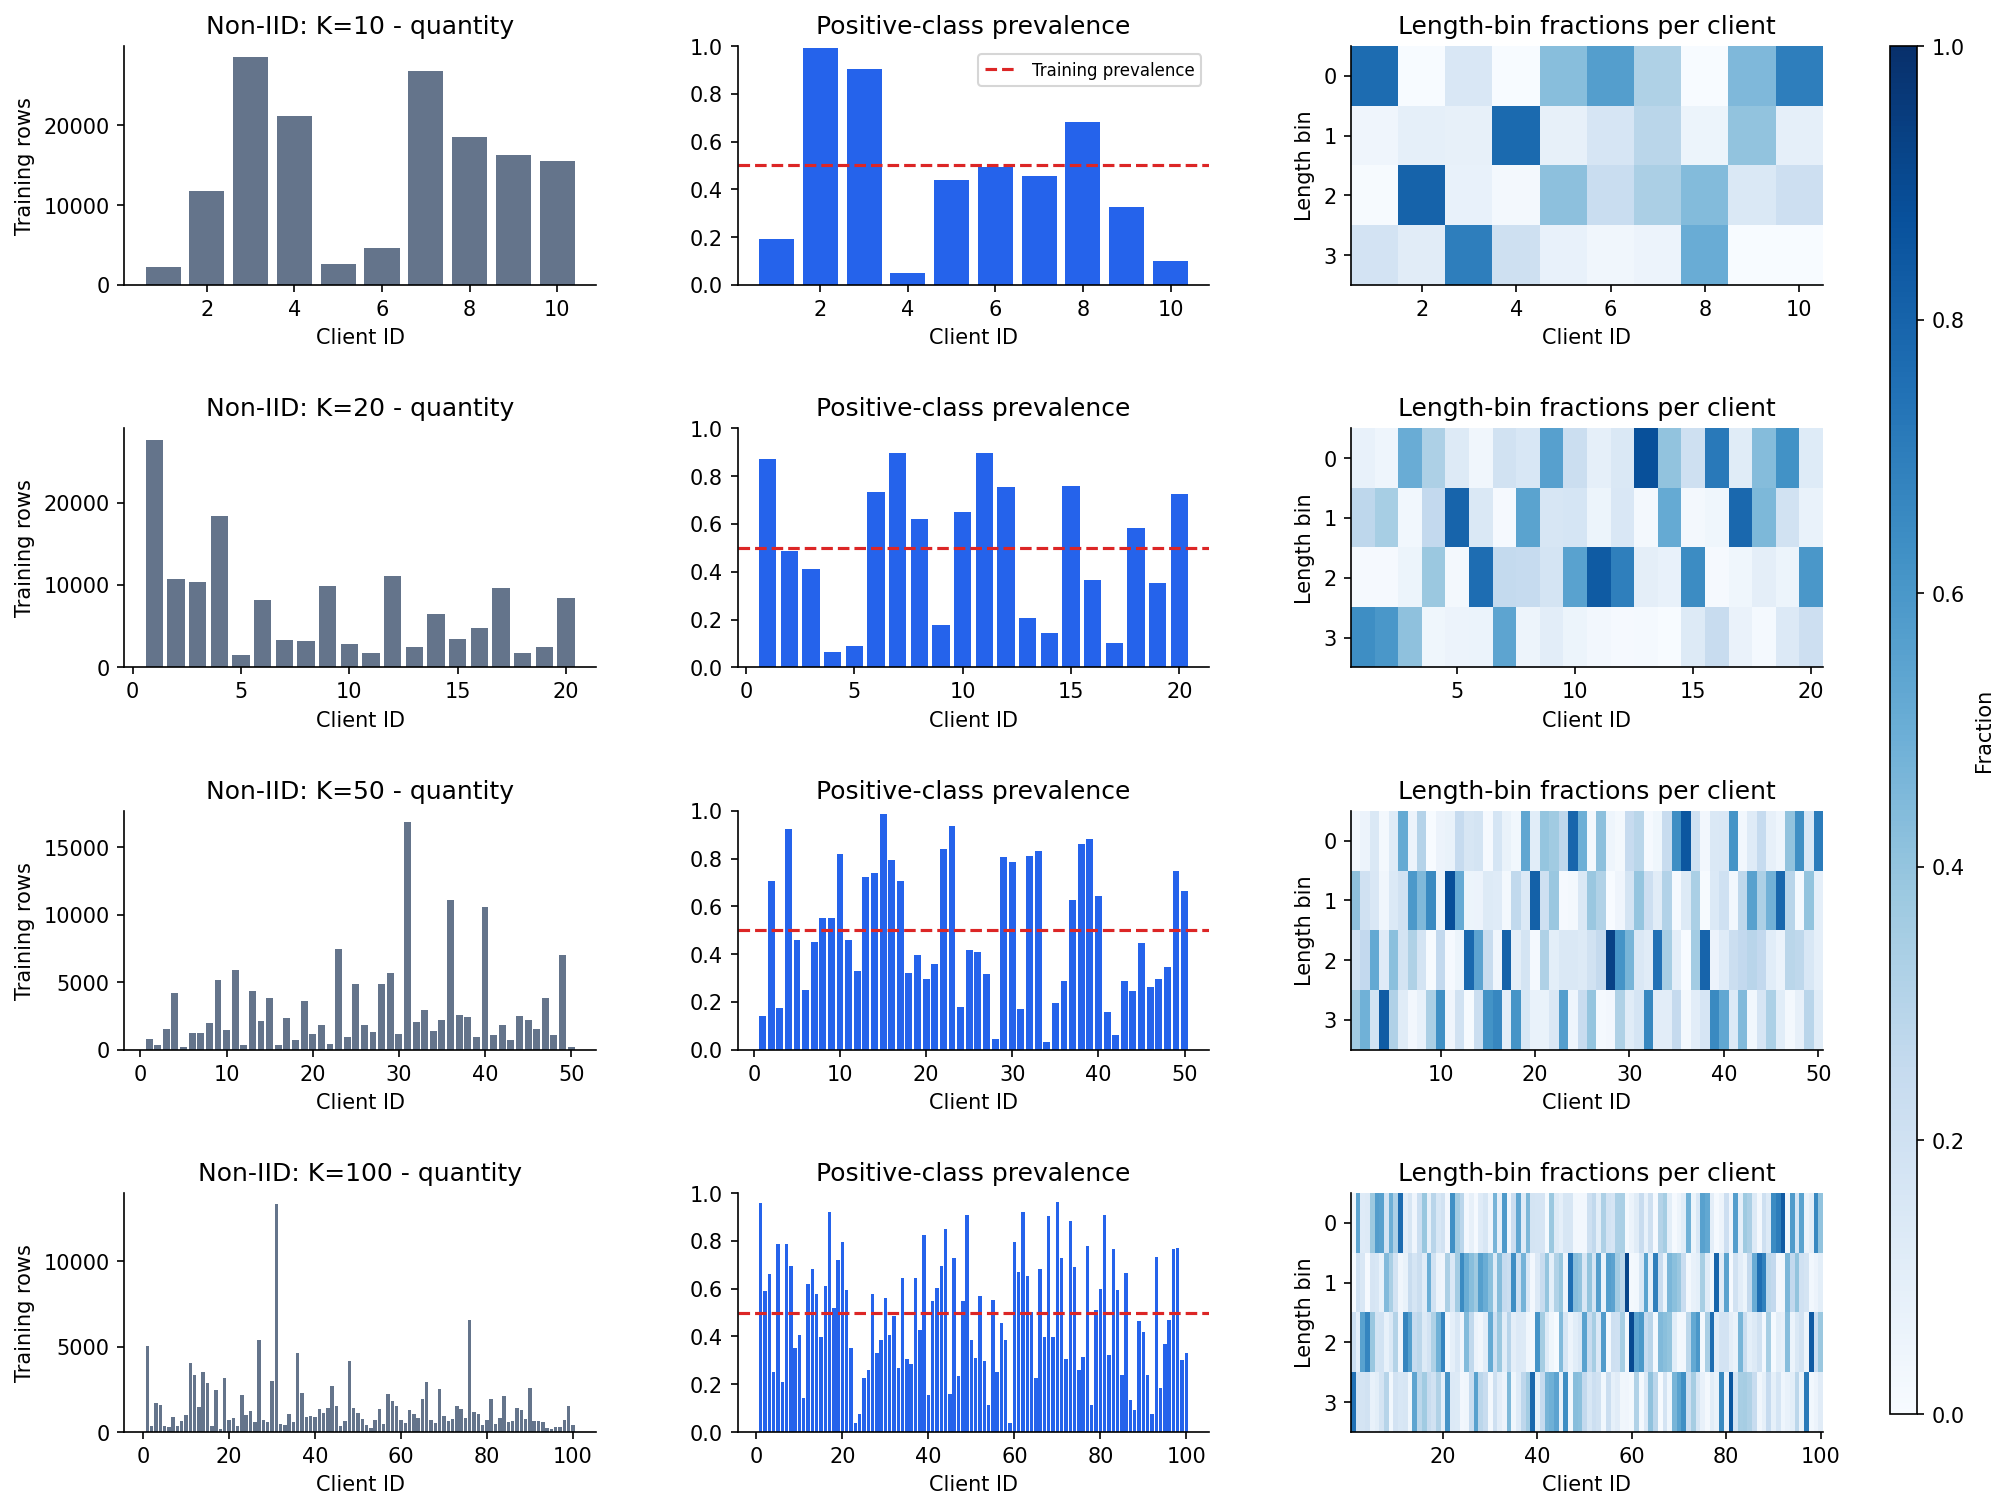

In [17]:
noniid_tables = []
for n_clients in CLIENT_COUNTS:
    for run_seed in REPEAT_SEEDS:
        plan = noniid_client_indices(train_strata, n_clients, run_seed)
        client_plans[('Non-IID', n_clients, run_seed)] = plan
        noniid_tables.append(describe_plan(plan, 'Non-IID', n_clients, run_seed))
noniid_partition_table = pd.concat(noniid_tables, ignore_index=True)
client_partition_table = pd.concat([iid_partition_table, noniid_partition_table], ignore_index=True)
partition_summary = partition_summary_table(client_partition_table)
display(partition_summary.query('mode == "Non-IID"').round(6))
floor_table = pd.DataFrame({'n_clients': CLIENT_COUNTS})
floor_table['reserved_rows'] = floor_table['n_clients'] * N_STRATA * NONIID_MIN_PER_STRATUM
floor_table['reserved_fraction'] = floor_table['reserved_rows'] / len(y_train)
print('Uniform floor used before heterogeneous allocation:')
display(floor_table)
for n_clients in CLIENT_COUNTS:
    for run_seed in REPEAT_SEEDS:
        iid = iid_partition_table.query('n_clients == @n_clients and seed == @run_seed')
        noniid = noniid_partition_table.query('n_clients == @n_clients and seed == @run_seed')
        assert noniid['joint_js_bits'].mean() > iid['joint_js_bits'].mean()
        assert noniid['label_js_bits'].mean() > iid['label_js_bits'].mean()
        assert noniid['conditional_length_js_bits'].mean() > iid['conditional_length_js_bits'].mean()
print('Non-IID label, joint and within-class length divergences exceed the matched IID values.')
print('All allocations reconstruct exactly the same pooled training distribution.')
plot_partitions(noniid_partition_table, 'Non-IID', '04_noniid_partitions.png')

### Non-IID - 10 clients

Independent local training under the measured heterogeneous partition.

In [18]:
run_and_report('Non-IID', 10)

Non-IID, K=10, seed=42: training 10 local pipelines
  completed 2/10
  completed 4/10
  completed 6/10
  completed 8/10
  completed 10/10
Non-IID | K=10 | seed=42
Validation-selected threshold: 0.48


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.9165              0.9172           0.9158       0.9165    0.9165   0.9711             0.9696       0.0806  1562  1535
           validation_selected    0.9164              0.9100           0.9243       0.9171    0.9164   0.9711             0.9696       0.0806  1405  1697
test       fixed_0.50             0.9142              0.9149           0.9134       0.9142    0.9142   0.9698             0.9686       0.0818  2008  1970
           validation_selected    0.9134              0.9073           0.9211       0.9141    0.9134   0.9698             0.9686       0.0818  1830  2184

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9197    0.9056    0.9126     23145
    suicide (1)     0.9073    0.9211    0.9141     23197

       accuracy                         0.9134     46342
      macro avg     0.9135    0.9134    0.9134     46342
   weighted avg     0.9135    0.9134    0.9134     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,2259.0,0.0498,5289.0,0.9542,0.0004
mean,14838.0,0.4638,14614.0,0.9749,0.0005
max,28506.0,0.9928,29745.0,0.9913,0.0007


Pipeline wall time: 231.86 s | Sum of model fit times: 607.10 s


### Non-IID - 20 clients

Independent local training under the measured heterogeneous partition.

In [19]:
run_and_report('Non-IID', 20)

Non-IID, K=20, seed=42: training 20 local pipelines
  completed 4/20
  completed 8/20
  completed 12/20
  completed 16/20
  completed 20/20
Non-IID | K=20 | seed=42
Validation-selected threshold: 0.47


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.9089              0.9109           0.9066       0.9088    0.9089   0.9673             0.9659       0.0801  1733  1646
           validation_selected    0.9092              0.8997           0.9212       0.9103    0.9091   0.9673             0.9659       0.0801  1463  1906
test       fixed_0.50             0.9065              0.9090           0.9036       0.9063    0.9065   0.9664             0.9648       0.0809  2236  2099
           validation_selected    0.9062              0.8977           0.9171       0.9073    0.9062   0.9664             0.9648       0.0809  1922  2425

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9151    0.8952    0.9051     23145
    suicide (1)     0.8977    0.9171    0.9073     23197

       accuracy                         0.9062     46342
      macro avg     0.9064    0.9062    0.9062     46342
   weighted avg     0.9064    0.9062    0.9062     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,1525.0,0.0635,2812.0,0.9216,0.0004
mean,7419.0,0.4945,10121.2,0.9643,0.0006
max,27637.0,0.8982,27672.0,0.9902,0.0009


Pipeline wall time: 266.29 s | Sum of model fit times: 787.90 s


### Non-IID - 50 clients

Independent local training under the measured heterogeneous partition.

In [20]:
run_and_report('Non-IID', 50)

Non-IID, K=50, seed=42: training 50 local pipelines
  completed 10/50
  completed 20/50
  completed 30/50
  completed 40/50
  completed 50/50
Non-IID | K=50 | seed=42
Validation-selected threshold: 0.52


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.8973              0.8852           0.9133       0.8990    0.8973   0.9610             0.9606       0.0862  1609  2198
           validation_selected    0.8994              0.8949           0.9053       0.9001    0.8994   0.9610             0.9606       0.0862  1757  1974
test       fixed_0.50             0.8958              0.8840           0.9114       0.8975    0.8958   0.9604             0.9602       0.0868  2056  2773
           validation_selected    0.8966              0.8925           0.9021       0.8973    0.8966   0.9604             0.9602       0.0868  2271  2521

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.9008    0.8911    0.8959     23145
    suicide (1)     0.8925    0.9021    0.8973     23197

       accuracy                         0.8966     46342
      macro avg     0.8966    0.8966    0.8966     46342
   weighted avg     0.8966    0.8966    0.8966     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,193.0,0.0327,907.0,0.8345,0.0004
mean,2967.6,0.4949,6455.3,0.9487,0.0007
max,16867.0,0.9846,17514.0,0.9860,0.0015


Pipeline wall time: 253.72 s | Sum of model fit times: 908.84 s


### Non-IID - 100 clients

Independent local training under the measured heterogeneous partition.

In [21]:
run_and_report('Non-IID', 100)

Non-IID, K=100, seed=42: training 100 local pipelines
  completed 20/100
  completed 40/100
  completed 60/100
  completed 80/100
  completed 100/100
Non-IID | K=100 | seed=42
Validation-selected threshold: 0.51


accuracy  precision_positive  recall_positive  f1_positive  f1_macro  roc_auc  average_precision  brier_score    fn    fp
split      policy                                                                                                                                        
validation fixed_0.50             0.8845              0.8741           0.8986       0.8862    0.8844   0.9509             0.9512       0.0970  1882  2403
           validation_selected    0.8859              0.8795           0.8947       0.8870    0.8859   0.9509             0.9512       0.0970  1955  2276
test       fixed_0.50             0.8829              0.8735           0.8958       0.8845    0.8829   0.9501             0.9503       0.0976  2418  3009
           validation_selected    0.8837              0.8783           0.8911       0.8846    0.8837   0.9501             0.9503       0.0976  2526  2865

Test classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-suicide (0)     0.8892    0.8762    0.8827     23145
    suicide (1)     0.8783    0.8911    0.8846     23197

       accuracy                         0.8837     46342
      macro avg     0.8838    0.8837    0.8837     46342
   weighted avg     0.8837    0.8837    0.8837     46342


,n_train,positive_fraction,vocabulary_size,test_token_coverage,test_all_oov_fraction
min,171.0,0.0376,1088.00,0.8505,0.0004
mean,1483.8,0.4930,4405.71,0.9324,0.0009
max,13328.0,0.9612,14729.00,0.9833,0.0014


Pipeline wall time: 164.26 s | Sum of model fit times: 602.19 s


## Compare the nine experiment configurations

The primary table uses a common 0.50 threshold to separate probability quality from
threshold selection. The next table uses each run's validation-selected threshold.
All scores are proportions on 0-1; FN/FP are counts. The fixed-threshold non-IID minus
IID differences compare the same client count and seed. Positive differences mean
non-IID scored higher for that metric; a decline is not forced by the code.

Changing K changes both training examples per local model and the ensemble size.
The comparison also includes changes to local Word2Vec quality. It does not isolate
an optimization penalty of a single global federated XGBoost model.

In [22]:
all_reports = central_reports + [report for reports in scenario_reports.values() for report in reports]
expected_local_models = 2 * sum(CLIENT_COUNTS) * len(REPEAT_SEEDS)
assert sum(r['n_clients'] for r in all_reports if r['mode'] != 'Centralized') == expected_local_models
comparison_rows = []
for report in all_reports:
    for policy in ['fixed_0.50', 'validation_selected']:
        test_metrics = report['metrics'].loc[('test', policy)]
        validation_metrics = report['metrics'].loc[('validation', policy)]
        comparison_rows.append({'mode': report['mode'], 'n_clients': report['n_clients'],
            'seed': report['seed'], 'policy': policy,
            'threshold': 0.5 if policy == 'fixed_0.50' else report['threshold'],
            'validation_f1_positive': validation_metrics['f1_positive'],
            **{f'test_{key}': value for key, value in test_metrics.items()},
            'mean_client_rows': report['local_summary']['n_train'].mean(),
            'mean_test_token_coverage': report['local_summary']['test_token_coverage'].mean(),
            'pipeline_wall_seconds': report['pipeline_wall_seconds'],
            'fit_seconds_sum': report['fit_seconds_sum']})
comparison_each_run = pd.DataFrame(comparison_rows)
comparison_mean = comparison_each_run.drop(columns='seed').groupby(['policy', 'mode', 'n_clients'], sort=False).mean()
comparison_std = comparison_each_run.drop(columns='seed').groupby(['policy', 'mode', 'n_clients'], sort=False).std(ddof=1)
main_columns = ['threshold', 'mean_client_rows', 'test_accuracy', 'test_precision_positive',
    'test_recall_positive', 'test_f1_positive', 'test_f1_macro', 'test_roc_auc',
    'test_average_precision', 'test_fn', 'test_fp', 'pipeline_wall_seconds']
print('PRIMARY: shared test set, fixed threshold 0.50')
display(comparison_mean.loc['fixed_0.50', main_columns].round(4))
print('SECONDARY: shared test set, validation-selected thresholds')
display(comparison_mean.loc['validation_selected', main_columns].round(4))
if len(REPEAT_SEEDS) > 1:
    print('Across-seed sample standard deviations, fixed threshold:')
    display(comparison_std.loc['fixed_0.50', main_columns].round(4))
else:
    print('One predefined seed: no across-run standard deviations or significance claims.')

delta_rows = []
for k in CLIENT_COUNTS:
    iid = comparison_mean.loc[('fixed_0.50', 'IID', k)]
    noniid = comparison_mean.loc[('fixed_0.50', 'Non-IID', k)]
    delta_rows.append({'n_clients': k,
        'accuracy_delta_pp': 100 * (noniid['test_accuracy'] - iid['test_accuracy']),
        'f1_positive_delta_pp': 100 * (noniid['test_f1_positive'] - iid['test_f1_positive']),
        'recall_positive_delta_pp': 100 * (noniid['test_recall_positive'] - iid['test_recall_positive']),
        'roc_auc_delta': noniid['test_roc_auc'] - iid['test_roc_auc'],
        'mean_joint_js_iid': partition_summary.query('mode == "IID" and n_clients == @k')['mean_joint_js_bits'].mean(),
        'mean_joint_js_noniid': partition_summary.query('mode == "Non-IID" and n_clients == @k')['mean_joint_js_bits'].mean()})
delta_table = pd.DataFrame(delta_rows).set_index('n_clients')
print('Non-IID minus matched IID (pp = percentage points):')
display(delta_table.round(4))
print('Measured client heterogeneity:')
display(partition_summary.set_index(['mode', 'n_clients', 'seed']).round(6))

PRIMARY: shared test set, fixed threshold 0.50


threshold  mean_client_rows  test_accuracy  test_precision_positive  test_recall_positive  test_f1_positive  test_f1_macro  test_roc_auc  \
mode        n_clients                                                                                                                                             
Centralized 1                0.5          148380.0         0.9197                   0.9188                0.9209            0.9199         0.9197        0.9752   
IID         10               0.5           14838.0         0.9151                   0.9124                0.9186            0.9154         0.9151        0.9724   
            20               0.5            7419.0         0.9087                   0.9056                0.9127            0.9092         0.9087        0.9685   
            50               0.5            2967.6         0.8926                   0.8864                0.9010            0.8936         0.8926        0.9583   
            100              0.5            1483.8         0.8695                   0.8565                0.8880            0.8720         0.8694        0.9435   
Non-IID     10               0.5           14838.0         0.9142                   0.9149                0.9134            0.9142         0.9142        0.9698   
            20               0.5            7419.0         0.9065                   0.9090                0.9036            0.9063         0.9065        0.9664   
            50               0.5            2967.6         0.8958                   0.8840                0.9114            0.8975         0.8958        0.9604   
            100              0.5            1483.8         0.8829                   0.8735                0.8958            0.8845         0.8829        0.9501   

                       test_average_precision  test_fn  test_fp  pipeline_wall_seconds  
mode        n_clients                                                                   
Centralized 1                          0.9744   1835.0   1887.0               484.6346  
IID         10                         0.9718   1889.0   2047.0               168.7363  
            20                         0.9680   2025.0   2206.0               172.7585  
            50                         0.9584   2297.0   2678.0               149.4345  
            100                        0.9450   2598.0   3450.0               190.5061  
Non-IID     10                         0.9686   2008.0   1970.0               231.8585  
            20                         0.9648   2236.0   2099.0               266.2852  
            50                         0.9602   2056.0   2773.0               253.7228  
            100                        0.9503   2418.0   3009.0               164.2552

SECONDARY: shared test set, validation-selected thresholds


threshold  mean_client_rows  test_accuracy  test_precision_positive  test_recall_positive  test_f1_positive  test_f1_macro  test_roc_auc  \
mode        n_clients                                                                                                                                             
Centralized 1               0.44          148380.0         0.9199                   0.9095                0.9329            0.9210         0.9199        0.9752   
IID         10              0.46           14838.0         0.9143                   0.9040                0.9273            0.9155         0.9143        0.9724   
            20              0.47            7419.0         0.9088                   0.8994                0.9209            0.9100         0.9088        0.9685   
            50              0.54            2967.6         0.8925                   0.8956                0.8889            0.8922         0.8925        0.9583   
            100             0.56            1483.8         0.8726                   0.8761                0.8683            0.8722         0.8726        0.9435   
Non-IID     10              0.48           14838.0         0.9134                   0.9073                0.9211            0.9141         0.9134        0.9698   
            20              0.47            7419.0         0.9062                   0.8977                0.9171            0.9073         0.9062        0.9664   
            50              0.52            2967.6         0.8966                   0.8925                0.9021            0.8973         0.8966        0.9604   
            100             0.51            1483.8         0.8837                   0.8783                0.8911            0.8846         0.8837        0.9501   

                       test_average_precision  test_fn  test_fp  pipeline_wall_seconds  
mode        n_clients                                                                   
Centralized 1                          0.9744   1557.0   2153.0               484.6346  
IID         10                         0.9718   1687.0   2285.0               168.7363  
            20                         0.9680   1835.0   2390.0               172.7585  
            50                         0.9584   2578.0   2403.0               149.4345  
            100                        0.9450   3054.0   2849.0               190.5061  
Non-IID     10                         0.9686   1830.0   2184.0               231.8585  
            20                         0.9648   1922.0   2425.0               266.2852  
            50                         0.9602   2271.0   2521.0               253.7228  
            100                        0.9503   2526.0   2865.0               164.2552

One predefined seed: no across-run standard deviations or significance claims.
Non-IID minus matched IID (pp = percentage points):


,accuracy_delta_pp,f1_positive_delta_pp,recall_positive_delta_pp,roc_auc_delta,mean_joint_js_iid,mean_joint_js_noniid
n_clients,,,,,,
10,-0.0906,-0.1264,-0.5130,-0.0025,0.0,0.3010
20,-0.2244,-0.2873,-0.9096,-0.0020,0.0,0.2985
50,0.3150,0.3858,1.0389,0.0021,0.0,0.2508
100,1.3400,1.2506,0.7760,0.0066,0.0,0.2206


Measured client heterogeneity:


min_rows  mean_rows  max_rows   size_cv  positive_fraction_min  positive_fraction_max  mean_label_js_bits  mean_joint_js_bits  \
mode    n_clients seed                                                                                                                                  
IID     10        42       14838    14838.0     14838  0.000000               0.500337               0.500404            0.000000            0.000000   
        20        42        7419     7419.0      7419  0.000000               0.500337               0.500472            0.000000            0.000000   
        50        42        2967     2967.6      2968  0.000165               0.500169               0.500506            0.000000            0.000000   
        100       42        1483     1483.8      1484  0.000270               0.500000               0.500674            0.000000            0.000001   
Non-IID 10        42        2259    14838.0     28506  0.605982               0.049840               0.992809            0.092155            0.301044   
        20        42        1525     7419.0     27637  0.852628               0.063458               0.898197            0.070970            0.298492   
        50        42         193     2967.6     16867  1.056667               0.032694               0.984619            0.065422            0.250804   
        100       42         171     1483.8     13328  1.144647               0.037574               0.961249            0.052461            0.220574   

                        mean_conditional_length_js_bits  weighted_joint_js_bits  
mode    n_clients seed                                                           
IID     10        42                           0.000000                0.000000  
        20        42                           0.000000                0.000000  
        50        42                           0.000000                0.000000  
        100       42                           0.000001                0.000001  
Non-IID 10        42                           0.224344                0.314248  
        20        42                           0.238670                0.281476  
        50        42                           0.199676                0.250982  
        100       42                           0.179015                0.222496

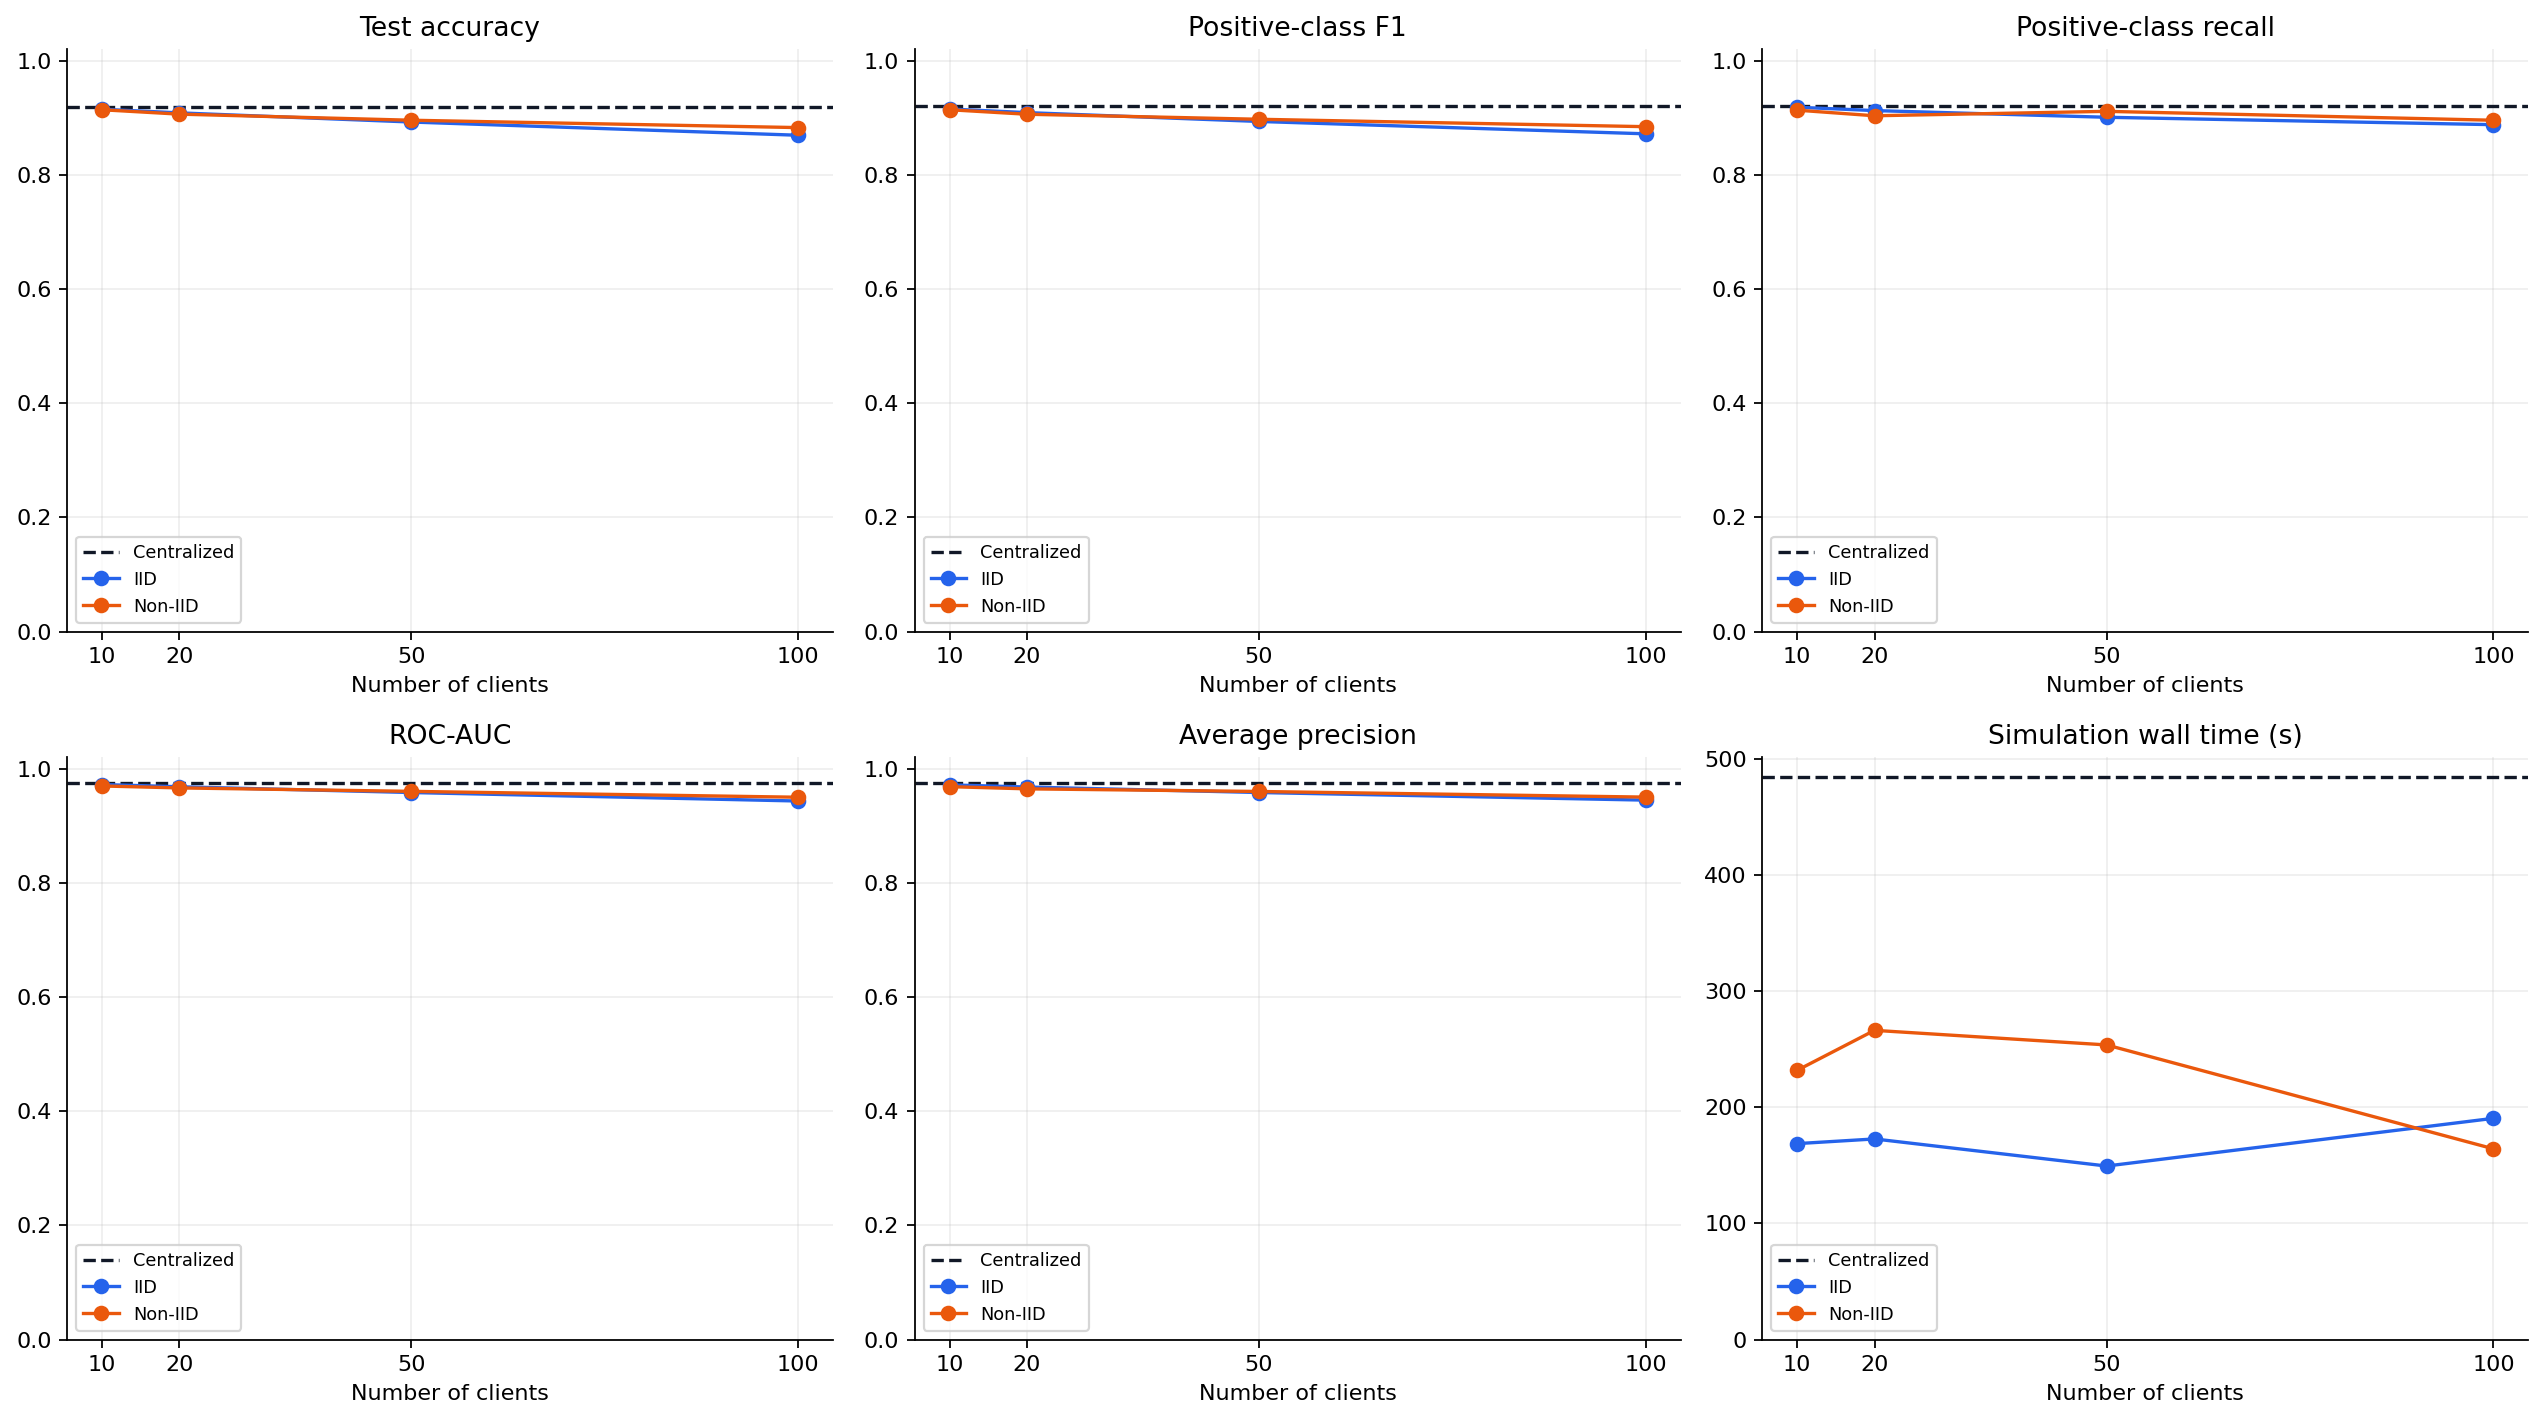

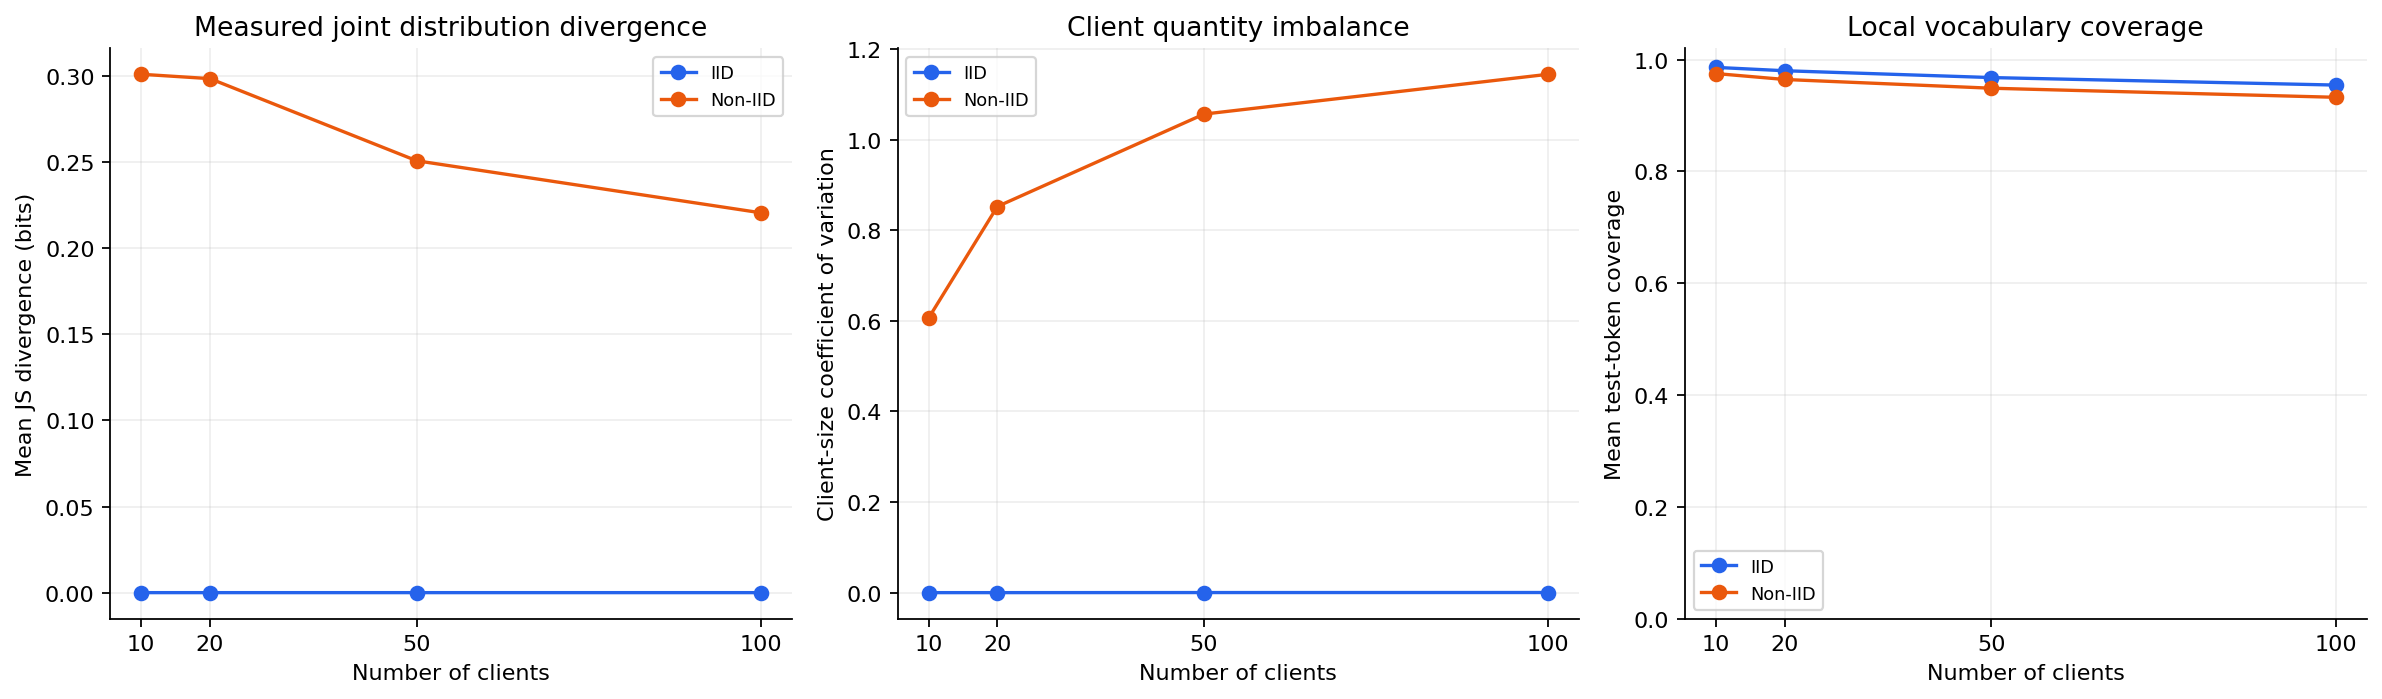

In [23]:
comparison_std = comparison_std.sort_index()  # Efficient partial MultiIndex selection.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fixed = comparison_mean.loc['fixed_0.50']
plots = [('test_accuracy', 'Test accuracy'), ('test_f1_positive', 'Positive-class F1'),
         ('test_recall_positive', 'Positive-class recall'), ('test_roc_auc', 'ROC-AUC'),
         ('test_average_precision', 'Average precision'), ('pipeline_wall_seconds', 'Simulation wall time (s)')]
for ax, (column, title) in zip(axes.flat, plots):
    central_value = fixed.loc[('Centralized', 1), column]
    ax.axhline(central_value, color='#111827', linestyle='--', label='Centralized')
    for mode, color in [('IID', '#2563eb'), ('Non-IID', '#ea580c')]:
        values = fixed.loc[mode].reindex(CLIENT_COUNTS)[column]
        deviations = comparison_std.loc[('fixed_0.50', mode)].reindex(CLIENT_COUNTS)[column]
        yerr = deviations.to_numpy() if len(REPEAT_SEEDS) > 1 else None
        ax.errorbar(CLIENT_COUNTS, values, yerr=yerr, color=color, marker='o', capsize=3, label=mode)
    ax.set(title=title, xlabel='Number of clients', xticks=CLIENT_COUNTS)
    if column != 'pipeline_wall_seconds':
        ax.set_ylim(0, 1.02)
    else:
        ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
show_figure(fig, '05_fixed_threshold_comparison.png')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for mode, color in [('IID', '#2563eb'), ('Non-IID', '#ea580c')]:
    s = partition_summary.query('mode == @mode').groupby('n_clients').mean(numeric_only=True).reindex(CLIENT_COUNTS)
    axes[0].plot(CLIENT_COUNTS, s['mean_joint_js_bits'], 'o-', color=color, label=mode)
    axes[1].plot(CLIENT_COUNTS, s['size_cv'], 'o-', color=color, label=mode)
    values = fixed.loc[mode].reindex(CLIENT_COUNTS)
    axes[2].plot(CLIENT_COUNTS, values['mean_test_token_coverage'], 'o-', color=color, label=mode)
axes[0].set(title='Measured joint distribution divergence', ylabel='Mean JS divergence (bits)')
axes[1].set(title='Client quantity imbalance', ylabel='Client-size coefficient of variation')
axes[2].set(title='Local vocabulary coverage', ylabel='Mean test-token coverage', ylim=(0, 1.02))
for ax in axes:
    ax.set(xlabel='Number of clients', xticks=CLIENT_COUNTS)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
show_figure(fig, '06_heterogeneity_and_coverage.png')

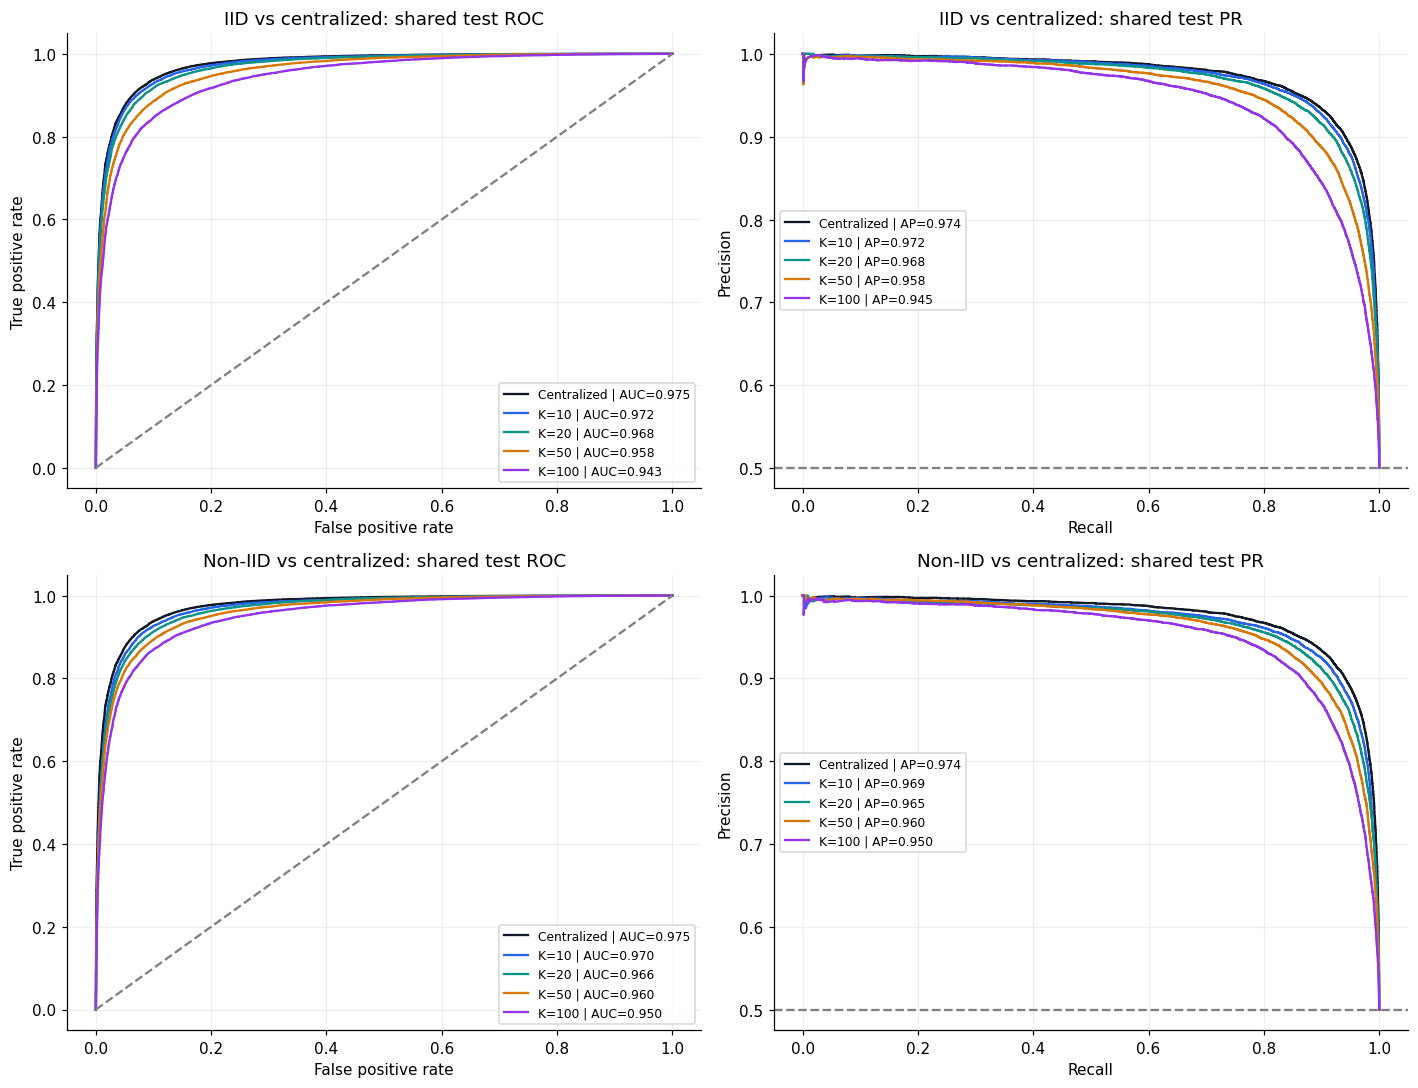

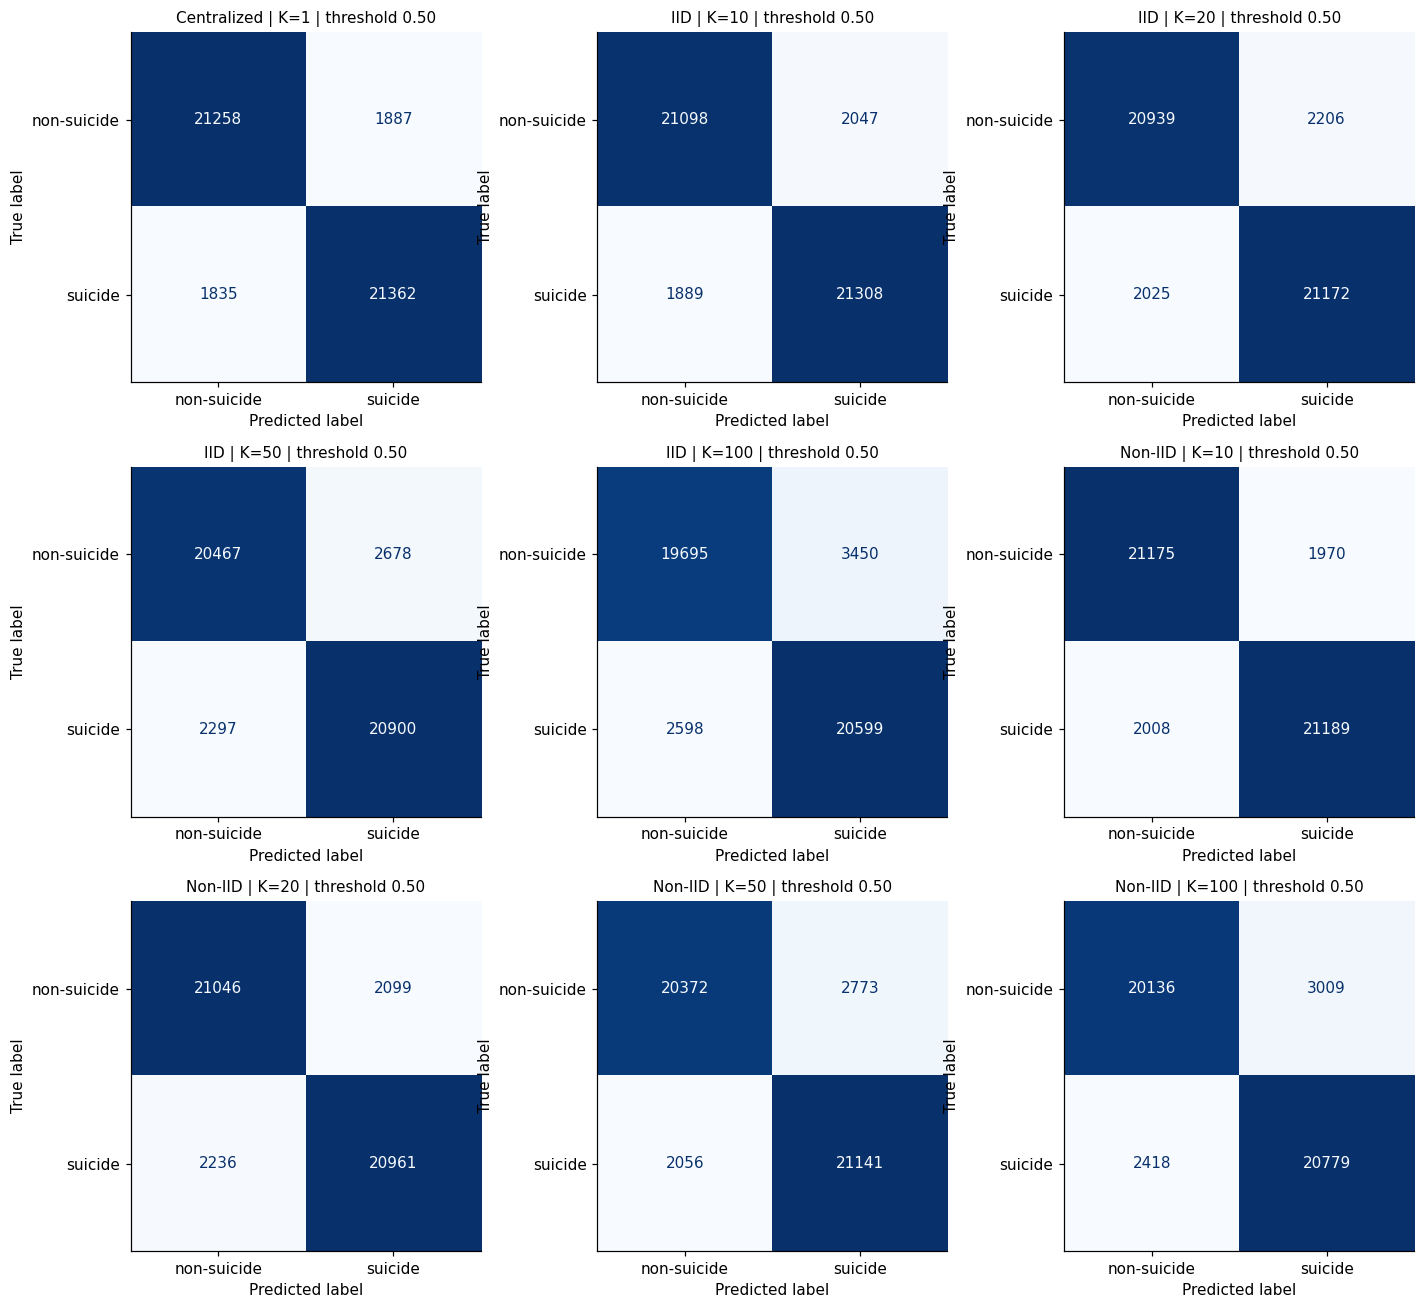

In [24]:
# First-seed curves show one fitted ensemble, without averaging model runs.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
central_first = central_reports[0]
for row, mode in enumerate(['IID', 'Non-IID']):
    reports = [central_first] + [scenario_reports[(mode, k)][0] for k in CLIENT_COUNTS]
    for report in reports:
        probability = report['test_probabilities']
        label = 'Centralized' if report['mode'] == 'Centralized' else f'K={report["n_clients"]}'
        color = '#111827' if report['mode'] == 'Centralized' else COLORS[report['n_clients']]
        fpr, tpr, _ = roc_curve(y_test, probability)
        axes[row, 0].plot(fpr, tpr, color=color,
                          label=f'{label} | AUC={roc_auc_score(y_test, probability):.3f}')
        precision, recall, _ = precision_recall_curve(y_test, probability)
        axes[row, 1].plot(recall, precision, color=color,
                          label=f'{label} | AP={average_precision_score(y_test, probability):.3f}')
    axes[row, 0].plot([0, 1], [0, 1], '--', color='gray')
    axes[row, 0].set(title=f'{mode} vs centralized: shared test ROC', xlabel='False positive rate', ylabel='True positive rate')
    axes[row, 1].axhline(y_test.mean(), linestyle='--', color='gray')
    axes[row, 1].set(title=f'{mode} vs centralized: shared test PR', xlabel='Recall', ylabel='Precision')
for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
show_figure(fig, '07_roc_pr.png')

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
first_reports = [central_first] + [scenario_reports[(mode, k)][0]
                                  for mode in ['IID', 'Non-IID'] for k in CLIENT_COUNTS]
for ax, report in zip(axes.flat, first_reports):
    ConfusionMatrixDisplay.from_predictions(y_test, report['test_probabilities'] >= 0.5,
        labels=[0, 1], display_labels=['non-suicide', 'suicide'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax)
    ax.set_title(f'{report["mode"]} | K={report["n_clients"]} | threshold 0.50', fontsize=10)
show_figure(fig, '08_confusion_matrices.png')

## Interpretation of this execution

The following text is calculated from the current run. It does not assume that
IID always wins or that adding clients always improves the ensemble.

In [25]:
base = comparison_mean.loc[('fixed_0.50', 'Centralized', 1)]
paragraphs = [f'The original data contained **{int(raw_audit["loaded_rows"]):,} rows** '
    f'and a positive prevalence of **{raw_distribution.loc["suicide", "fraction"]:.2%}**. '
    f'After the documented quality checks, the common split contains **{len(y_train):,} training**, '
    f'**{len(y_validation):,} validation** and **{len(y_test):,} test** rows.',
    f'At the common 0.50 threshold, the centralized baseline has test accuracy '
    f'**{base["test_accuracy"]:.2%}**, positive-class F1 **{base["test_f1_positive"]:.4f}**, '
    f'recall **{base["test_recall_positive"]:.2%}**, and ROC-AUC **{base["test_roc_auc"]:.4f}**.']
for k in CLIENT_COUNTS:
    iid = comparison_mean.loc[('fixed_0.50', 'IID', k)]
    noniid = comparison_mean.loc[('fixed_0.50', 'Non-IID', k)]
    delta = delta_table.loc[k]
    paragraphs.append(f'With **{k} clients**, IID positive-class F1 is **{iid["test_f1_positive"]:.4f}** '
        f'and non-IID F1 is **{noniid["test_f1_positive"]:.4f}**; the paired configuration difference '
        f'is **{delta["f1_positive_delta_pp"]:+.2f} percentage points**. Mean joint JS divergence '
        f'changes from **{delta["mean_joint_js_iid"]:.6f}** to **{delta["mean_joint_js_noniid"]:.4f} bits**. '
        f'The non-IID versus centralized F1 difference is '
        f'**{100 * (noniid["test_f1_positive"] - base["test_f1_positive"]):+.2f} percentage points**.')
paragraphs.extend([
    'Compare the fixed and validation-selected threshold tables together. Their difference reflects '
    'the decision cutoff as well as the fitted probability scores. ROC-AUC and AP do not depend on '
    'that cutoff. An F1-selected threshold does not guarantee a required recall or calibration.',
    'The non-IID experiment changes label balance, conditional text-length distributions and client '
    'sizes together. The result measures this combined stress test. A separate label-only, quantity-only '
    'and length-only ablation would be needed to attribute the change to individual sources.',
    f'This execution uses **{len(REPEAT_SEEDS)} predefined seed(s)** and one fixed data split. '
    'The observed differences alone do not demonstrate statistical significance or generalization '
    'across institutions. These social-media labels are not a clinical diagnosis or validation of '
    'performance on clinical interviews.'
])
display(Markdown('\n\n'.join(paragraphs)))

The original data contained **232,074 rows** and a positive prevalence of **50.00%**. After the documented quality checks, the common split contains **148,380 training**, **37,086 validation** and **46,342 test** rows.

At the common 0.50 threshold, the centralized baseline has test accuracy **91.97%**, positive-class F1 **0.9199**, recall **92.09%**, and ROC-AUC **0.9752**.

With **10 clients**, IID positive-class F1 is **0.9154** and non-IID F1 is **0.9142**; the paired configuration difference is **-0.13 percentage points**. Mean joint JS divergence changes from **0.000000** to **0.3010 bits**. The non-IID versus centralized F1 difference is **-0.57 percentage points**.

With **20 clients**, IID positive-class F1 is **0.9092** and non-IID F1 is **0.9063**; the paired configuration difference is **-0.29 percentage points**. Mean joint JS divergence changes from **0.000000** to **0.2985 bits**. The non-IID versus centralized F1 difference is **-1.36 percentage points**.

With **50 clients**, IID positive-class F1 is **0.8936** and non-IID F1 is **0.8975**; the paired configuration difference is **+0.39 percentage points**. Mean joint JS divergence changes from **0.000000** to **0.2508 bits**. The non-IID versus centralized F1 difference is **-2.24 percentage points**.

With **100 clients**, IID positive-class F1 is **0.8720** and non-IID F1 is **0.8845**; the paired configuration difference is **+1.25 percentage points**. Mean joint JS divergence changes from **0.000001** to **0.2206 bits**. The non-IID versus centralized F1 difference is **-3.54 percentage points**.

Compare the fixed and validation-selected threshold tables together. Their difference reflects the decision cutoff as well as the fitted probability scores. ROC-AUC and AP do not depend on that cutoff. An F1-selected threshold does not guarantee a required recall or calibration.

The non-IID experiment changes label balance, conditional text-length distributions and client sizes together. The result measures this combined stress test. A separate label-only, quantity-only and length-only ablation would be needed to attribute the change to individual sources.

This execution uses **1 predefined seed(s)** and one fixed data split. The observed differences alone do not demonstrate statistical significance or generalization across institutions. These social-media labels are not a clinical diagnosis or validation of performance on clinical interviews.

## Reproducibility audit and exports

The audit verifies complete/disjoint client coverage, pooled-distribution preservation,
common held-out row IDs, legal probability ranges, validation-only threshold selection,
and a direct recomputation of server aggregation. It also checks the accelerated mean
embedding against direct word-vector averaging, including repeated and unknown words.

With `SAVE_OUTPUTS=True`, the notebook writes CSV tables, figures, quality audits and
metadata into `xgboost_distribution_results/`. No raw text is exported. These auxiliary files are recreated by running the notebook.

In [26]:
audit_rows = []
for report in all_reports:
    probability = report['test_probabilities']
    assert report['test_ids_digest'] == test_batch.id_digest
    assert report['validation_ids_digest'] == validation_batch.id_digest
    assert len(probability) == len(y_test) and np.isfinite(probability).all()
    assert np.all((probability >= 0) & (probability <= 1))
    frozen, _ = select_threshold(y_validation, report['validation_probabilities'])
    assert frozen == report['threshold']
    for policy, threshold in [('fixed_0.50', 0.5), ('validation_selected', report['threshold'])]:
        recomputed = metric_summary(y_test, probability, threshold)
        stored = report['metrics'].loc[('test', policy)]
        for metric, value in recomputed.items():
            np.testing.assert_allclose(stored[metric], value, rtol=1e-12, atol=1e-12)
    audit_rows.append({'mode': report['mode'], 'n_clients': report['n_clients'], 'seed': report['seed'],
        'n_test': len(probability), 'test_ids_match': True, 'metrics_recomputed': True,
        'threshold_from_validation': True, 'probabilities_valid': True})
assert embedding_invariant_passed
audit_table = pd.DataFrame(audit_rows)
display(audit_table)

run_metadata = {'source_notebook': 'federated_xgboost_10_20_50_100(2).ipynb',
    'dataset_source': 'nikhileswarkomati/suicide-watch', 'dataset_file': csv_path.name,
    'dataset_sha256': dataset_sha256, 'original_rows': int(raw_audit['loaded_rows']),
    'split_counts': {name: len(frame) for name, frame in partitions.items()},
    'versions': versions, 'split_seed': SEED, 'repeat_seeds': list(REPEAT_SEEDS),
    'client_counts': list(CLIENT_COUNTS), 'length_cut_points_train_only': length_cuts.tolist(),
    'w2v_config': W2V_CONFIG, 'xgb_config': XGB_CONFIG,
    'noniid': {'alpha': NONIID_ALPHA, 'quantity_sigma': NONIID_QUANTITY_SIGMA,
               'min_rows_per_stratum_per_client': NONIID_MIN_PER_STRATUM},
    'method': 'One-round, sample-count-weighted federated prediction ensemble',
    'primary_threshold': 0.5, 'secondary_threshold': 'validation positive-class F1 only',
    'trained_central_pipelines': len(central_reports), 'trained_local_pipelines': expected_local_models,
    'max_parallel_clients': MAX_PARALLEL_CLIENTS, 'xgb_threads_per_client': XGB_THREADS_PER_CLIENT,
    'test_ids_digest': test_batch.id_digest, 'validation_ids_digest': validation_batch.id_digest,
    'query_preparation_seconds': query_preparation_seconds, 'run_started_utc': RUN_STARTED_UTC,
    'run_finished_utc': datetime.now(timezone.utc).isoformat(),
    'audit': {'embedding_direct_mean_passed': embedding_invariant_passed,
              'all_test_metrics_recomputed': True, 'partition_coverage_and_pooled_distribution_passed': True}}

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    comparison_each_run.to_csv(OUTPUT_DIR / 'comparison_each_run.csv', index=False)
    comparison_mean.to_csv(OUTPUT_DIR / 'comparison_mean.csv')
    comparison_std.to_csv(OUTPUT_DIR / 'comparison_std.csv')
    delta_table.to_csv(OUTPUT_DIR / 'noniid_minus_iid.csv')
    client_partition_table.to_csv(OUTPUT_DIR / 'client_distribution_diagnostics.csv', index=False)
    partition_summary.to_csv(OUTPUT_DIR / 'partition_summary.csv', index=False)
    split_table.to_csv(OUTPUT_DIR / 'data_split_counts.csv')
    raw_distribution.to_csv(OUTPUT_DIR / 'original_class_distribution.csv')
    raw_length_summary.to_csv(OUTPUT_DIR / 'original_text_length_distribution.csv')
    clean_length_summary.to_csv(OUTPUT_DIR / 'clean_text_length_distribution.csv')
    raw_audit.to_csv(OUTPUT_DIR / 'raw_quality_audit.csv')
    cleaning_audit.to_csv(OUTPUT_DIR / 'cleaning_audit.csv')
    top_words.to_csv(OUTPUT_DIR / 'training_top_words.csv', index=False)
    audit_table.to_csv(OUTPUT_DIR / 'execution_audit.csv', index=False)
    local_diagnostics = []
    for report in all_reports:
        stem = f'{report["mode"].lower().replace("-", "")}_K{report["n_clients"]}_seed{report["seed"]}'
        report['metrics'].to_csv(OUTPUT_DIR / f'{stem}_metrics.csv')
        report['threshold_curve'].to_csv(OUTPUT_DIR / f'{stem}_validation_thresholds.csv', index=False)
        local_diagnostics.append(report['local_summary'].assign(mode=report['mode'],
            n_clients=report['n_clients'], seed=report['seed']))
    pd.concat(local_diagnostics, ignore_index=True).to_csv(OUTPUT_DIR / 'local_model_diagnostics.csv', index=False)
    (OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(run_metadata, indent=2), encoding='utf-8')
    print('Result exports:', OUTPUT_DIR.resolve())
print(f'Completed {len(all_reports)} experiment runs: {len(central_reports)} centralized and '
      f'{expected_local_models} local pipelines. All audit checks passed.')

,mode,n_clients,seed,n_test,test_ids_match,metrics_recomputed,threshold_from_validation,probabilities_valid
0,Centralized,1,42,46342,True,True,True,True
1,IID,10,42,46342,True,True,True,True
2,IID,20,42,46342,True,True,True,True
3,IID,50,42,46342,True,True,True,True
4,IID,100,42,46342,True,True,True,True
5,Non-IID,10,42,46342,True,True,True,True
6,Non-IID,20,42,46342,True,True,True,True
7,Non-IID,50,42,46342,True,True,True,True
8,Non-IID,100,42,46342,True,True,True,True


Result exports: /workspace/scratch/33c44c6145c6/xgboost_distribution_results
Completed 9 experiment runs: 1 centralized and 360 local pipelines. All audit checks passed.


## Scope and primary references

- **Training privacy:** this is an in-process simulation. It provides no encryption,
  differential privacy, secure aggregation or privacy proof. Prediction requests are
  visible to the clients. Output probabilities and diagnostics may disclose information.
- **Availability:** all clients participate and use the same computational budget.
  Dropouts, slow devices, bandwidth constraints, adversaries and temporal drift are not
  simulated. Non-IID here refers to data heterogeneity.
- **Data distribution:** eight joint label/length bins describe selected dimensions of
  an empirical text distribution. Similar marginals do not imply identical full text
  distributions. The mixed non-IID construction is an adaptation inspired by Dirichlet
  partitioning, not an exact reproduction of Hsu et al.'s visual-classification setup.
- **Evaluation:** the original data split is retained for comparable experiments. A test
  set previously inspected in earlier work does not become a new unseen test set by
  revising this notebook. Independent external validation remains a separate experiment.
- **Meaning of the baseline:** the centralized pipeline has access to all training texts
  for its representation; each client has only local training texts. Differences therefore
  include representation quality, sample size, and aggregation effects.
- **Calibration and deployment:** raw XGBoost probabilities are not guaranteed to be
  calibrated. The balanced social-media dataset does not establish real-world alert
  prevalence, clinical validity or deployment performance.

The same alpha and quantity sigma do not guarantee equal realized heterogeneity across different client counts; compare the per-K divergence diagnostics. The common test pool measures aggregate performance, rather than personalized performance on each client population.

Primary sources, checked for this revision:

1. [Original Kaggle dataset: Suicide and Depression Detection](https://www.kaggle.com/datasets/nikhileswarkomati/suicide-watch).
2. [Hsu, Qi and Brown (2019): Measuring the Effects of Non-Identical Data Distribution for Federated Visual Classification](https://arxiv.org/abs/1909.06335).
3. [Gensim: Word2Vec API](https://radimrehurek.com/gensim/models/word2vec.html).
4. [XGBoost: Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).
5. [scikit-learn: data leakage and common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
6. [SciPy: Jensen-Shannon distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jensenshannon.html).